# PyTorch Fundamentals: Zero to Confident
**A Professional Deep Dive from First Principles to Fashion-MNIST Production Classifier**

Welcome to PyTorch Fundamentals! This notebook is your comprehensive, step-by-step masterclass in PyTorch. Whether you are running on an ordinary CPU or an 8GB NVIDIA GPU (like an RTX 4060), this notebook automatically detects your hardware and guides you through core deep learning engineering practices.

---

## Pedagogical Glossary
Here is our master reference table of terms. Every technical word is defined in plain language when it is first encountered.

| Term | One-Sentence Plain Definition |
| :--- | :--- |
| **Tensor** | A multi-dimensional grid of numbers (like a list, a spreadsheet, or a 3D cube) stored in computer memory. |
| **Rank / Dimension (`ndim`)** | The number of directions or axes along which numbers are arranged in a tensor. |
| **Shape** | A tuple of integers stating exactly how many numbers exist along each axis of a tensor. |
| **Data Type (`dtype`)** | The binary format and precision used to store each number in memory (e.g., 32-bit float, 64-bit integer). |
| **Indexing** | Selecting specific individual numbers or slices from a tensor using numeric coordinates. |
| **Slicing** | Extracting a sub-window of elements along an axis using start, stop, and step bounds (`start:stop:step`). |
| **Broadcasting** | PyTorch's rule-based stretching of smaller tensors across dimensions of size 1 so arithmetic works without copying data. |
| **Stride** | The number of memory steps needed to jump to the next element along each dimension in physical RAM. |
| **View** | A new tensor metadata window looking at the exact same physical memory buffer with a different shape or stride. |
| **Reshape** | A method that returns a view if memory is contiguous, or creates a memory copy if it is not. |
| **Contiguity** | Storing tensor elements sequentially in memory in the exact order traversed by row-major indexing. |
| **Device** | The physical hardware processor and memory where a tensor resides (either system RAM `cpu` or graphics VRAM `cuda:0`). |
| **NumPy Interoperability** | The ability to share memory directly between PyTorch CPU tensors and NumPy ndarrays without overhead. |


## Pedagogical Glossary
Here is our master reference table of terms. Every technical word is defined in plain language when it is first encountered.

| Term | One-Sentence Plain Definition |
| :--- | :--- |
| **Tensor** | A multi-dimensional grid of numbers (like a list, a spreadsheet, or a 3D cube) stored in computer memory. |
| **Rank / Dimension (`ndim`)** | The number of directions or axes along which numbers are arranged in a tensor. |
| **Shape** | A tuple of integers stating exactly how many numbers exist along each axis of a tensor. |
| **Data Type (`dtype`)** | The binary format and precision used to store each number in memory (e.g., 32-bit float, 64-bit integer). |
| **Indexing** | Selecting specific individual numbers or slices from a tensor using numeric coordinates. |
| **Slicing** | Extracting a sub-window of elements along an axis using start, stop, and step bounds (`start:stop:step`). |
| **Broadcasting** | PyTorch's rule-based stretching of smaller tensors across dimensions of size 1 so arithmetic works without copying data. |
| **Stride** | The number of memory steps needed to jump to the next element along each dimension in physical RAM. |
| **View** | A new tensor metadata window looking at the exact same physical memory buffer with a different shape or stride. |
| **Reshape** | A method that returns a view if memory is contiguous, or creates a memory copy if it is not. |
| **Contiguity** | Storing tensor elements sequentially in memory in the exact order traversed by row-major indexing. |
| **Device** | The physical hardware processor and memory where a tensor resides (either system RAM `cpu` or graphics VRAM `cuda:0`). |
| **NumPy Interoperability** | The ability to share memory directly between PyTorch CPU tensors and NumPy ndarrays without overhead. |
| **Autograd** | PyTorch's automatic differentiation engine that records math operations and calculates exact derivatives. |
| **Computational Graph** | A directed flowchart of nodes (tensors) and edges (math operations) that tracks how outputs were produced. |
| **Dynamic Graph (Define-by-Run)** | A computational graph built step-by-step at runtime as code executes, allowing dynamic Python loops and conditionals. |
| **`requires_grad`** | A tensor flag that tells PyTorch to record every math operation applied to it for derivative calculations. |
| **Backward Pass (`.backward()`)** | Traversing the computational graph in reverse to calculate the gradient of a final scalar with respect to all leaf tensors. |
| **Gradient (`.grad`)** | A tensor storing the rate of change of the loss with respect to a parameter, indicating how to tweak it to reduce error. |
| **Leaf Tensor** | A root tensor created directly by the user (like weights or inputs), rather than produced by an intermediate math operation. |
| **`torch.no_grad()`** | A context manager that disables graph building to save memory and speed up evaluation during inference. |
| **`.detach()`** | A method that disconnects a tensor from the computational graph so gradients can never flow backwards through it. |
| **`nn.Module`** | The base class for all neural network blueprints in PyTorch, managing layer hierarchy and learnable parameters. |
| **`__init__` vs `forward`** | `__init__` instantiates and allocates layer parameters; `forward` defines the calculation path when data flows through. |
| **Linear Layer (`nn.Linear`)** | A fully connected layer that applies the affine transformation $y = x W^T + b$ to input features. |
| **Activation Function (ReLU)** | A non-linear element-wise function $\max(0, x)$ that enables neural networks to learn non-linear patterns. |
| **Dropout (`nn.Dropout`)** | A regularization technique that randomly zeroes out activations during training to prevent co-adaptation of neurons. |
| **Logits** | The raw, unnormalized scalar scores output by the final linear layer of a classification model before softmax. |
| **`parameters()`** | An iterator yielding all learnable weight and bias tensors registered inside a module. |
| **`state_dict()`** | A standard Python dictionary mapping the string name of every parameter and buffer to its underlying tensor. |
| **Dataset (`torch.utils.data.Dataset`)** | An abstract class representing a data collection, implementing `__len__` and `__getitem__`. |
| **Transform (`torchvision.transforms`)** | Deterministic or stochastic functions that convert, crop, resize, or normalize raw samples into standardized tensors. |
| **Normalization** | Shifting and scaling pixel values to mean 0 and standard deviation 1 to stabilize gradient descent. |
| **DataLoader (`torch.utils.data.DataLoader`)** | An iterator that batches, shuffles, and loads dataset samples in parallel using background worker threads/processes. |
| **Batch Size** | The number of training samples processed simultaneously in a single forward/backward pass. |
| **`num_workers`** | The number of background subprocesses used by DataLoader to load data asynchronously in parallel. |
| **Cross-Entropy Loss (`nn.CrossEntropyLoss`)** | A criterion that measures prediction penalty by combining LogSoftmax and Negative Log-Likelihood loss in one stable step. |
| **Softmax** | An activation function that exponentiates and normalizes raw logits into probabilities summing to $1.0$. |
| **Optimizer (`torch.optim`)** | An optimization algorithm (such as Adam or SGD) that updates model weights based on computed gradients. |
| **Learning Rate** | A scaling hyperparameter controlling the size of the step the optimizer takes in the gradient direction. |
| **The 5-Step Loop** | The canonical PyTorch sequence: `zero_grad()` $\to$ `forward` $\to$ `loss` $\to$ `backward()` $\to$ `step()`. |
| **Validation Split** | A held-out portion of data never used to update weights, used solely to evaluate generalization accuracy. |
| **Evaluation Mode (`model.eval()`)** | A module switch that disables dropout and uses frozen population statistics in normalization layers. |
| **Accuracy** | The percentage of test/validation samples where the model's top logit corresponds to the true target label. |
| **Gradient Accumulation** | PyTorch's default behavior of adding new gradients to `.grad` instead of replacing them. |
| **`torch.cuda.memory_allocated()`** | A CUDA diagnostic function returning the exact number of bytes currently occupied by active tensor storage in GPU VRAM. |
| **`.item()`** | A tensor method that extracts a single scalar number as a native Python `float` or `int`, severing all graph connections. |
| **Model Checkpoint** | A serialized dictionary bundle containing model weights, optimizer buffers, epoch count, and performance metrics. |
| **`map_location`** | An argument in `torch.load` specifying which hardware device (e.g. CPU or CUDA) the loaded tensors should be placed on. |
| **Caching Allocator** | PyTorch's internal GPU memory manager that reserves chunks of VRAM from the OS to avoid slow system reallocations. |
| **`torch.cuda.empty_cache()`** | Releases all unused cached memory held by the caching allocator back to the operating system. |
| **Mixed Precision (AMP)** | Performing compute-heavy operations in 16-bit precision while keeping sensitive math in 32-bit precision. |
| **`torch.amp.autocast`** | A context manager that automatically selects optimal floating-point precision (FP16/BF16 vs FP32) per operation. |
| **`GradScaler`** | An object that scales gradients by a factor (e.g. 65,536) before backprop to prevent floating-point underflow in FP16. |
| **Gradient Underflow** | When tiny gradient numbers are smaller than the smallest representable number in 16-bit float, rounding down to 0.0. |


In [1]:
# 1. Import core PyTorch library
import torch
# 2. Import numerical computing library for array conversions
import numpy as np
# 3. Import plotting library for visual diagnostic plots
import matplotlib.pyplot as plt

# 4. Check if CUDA (GPU support) is available on this system
use_cuda = torch.cuda.is_available()
# 5. Automatically select the GPU device if available, otherwise fallback to CPU
device = torch.device("cuda:0" if use_cuda else "cpu")

# 6. Print system configuration details
print(f"PyTorch Version: {torch.__version__}")
print(f"Device Selected: {device}")
if use_cuda:
    print(f"GPU Hardware: {torch.cuda.get_device_name(0)}")
    print(f"Available VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


PyTorch Version: 2.14.0+cu130
Device Selected: cuda:0
GPU Hardware: NVIDIA GeForce RTX 4060 Laptop GPU
Available VRAM: 8.00 GB


**What we just saw:**
PyTorch confirmed our execution device. If you have an NVIDIA GPU, `device` will point to `cuda:0` with its VRAM capacity reported; otherwise, it cleanly defaults to your system `cpu`.

---
# Step 1: Tensors — Creation, Shapes, Dtypes, Indexing, Broadcasting, Views, GPU & NumPy

Tensors are the fundamental data structure in PyTorch. Everything from input image pixels to layer weights and loss gradients is represented as a tensor.


### 1.1 Tensor Creation
**1. The idea in ONE plain sentence:**
A tensor is a multi-dimensional array of numbers stored in contiguous blocks of computer memory.

**2. Real-life analogy:**
Think of a tensor as an ice-cube tray where each individual pocket holds a single number. A 1D tray is a single row, a 2D tray is a flat rectangular tray, and a 3D tray is a stack of rectangular trays inside a freezer.

**3. Tiny example worked by hand:**
- A scalar (0D): just the number `7.0`.
- A 1D vector of length 3: `[1.0, 2.0, 3.0]`.
- A 2D matrix of shape (2, 3):
  $$\begin{bmatrix} 1.0 & 2.0 & 3.0 \\ 4.0 & 5.0 & 6.0 \end{bmatrix}$$
  It has 2 rows and 3 columns, making 6 numbers in total.

**4. The math with every symbol explained in words:**
A tensor $T \in \mathbb{R}^{d_1 \times d_2 \times \dots \times d_k}$ is a mathematical object indexed by $k$ coordinates $(i_1, i_2, \dots, i_k)$.
- $\mathbb{R}$: Real numbers (numbers with decimal points).
- $k$: The rank (number of dimensions or axes).
- $d_m$: The size (length) along axis $m$.
- Total elements $N = \prod_{m=1}^k d_m$ (the product of all dimension lengths).

**5. Code explained line by line:**
Let's create tensors from Python lists, and using built-in generators (`zeros`, `ones`, `rand`).


In [2]:
# 1. Create a 1D tensor directly from a Python list
t_1d = torch.tensor([1.0, 2.0, 3.0])
# 2. Create a 2D tensor (matrix) from nested Python lists
t_2d = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
# 3. Create a tensor filled with zeros of shape (2, 3)
t_zeros = torch.zeros(2, 3)
# 4. Create a tensor filled with ones of shape (2, 3)
t_ones = torch.ones(2, 3)
# 5. Create a tensor with uniformly distributed random numbers in [0, 1)
t_rand = torch.rand(2, 3)

# 6. Display tensor values and their exact shapes
print("t_1d shape:", t_1d.shape, "| elements:", t_1d)
print("t_2d shape:", t_2d.shape, "| elements:\n", t_2d)
print("t_zeros shape:", t_zeros.shape)
print("t_rand shape:", t_rand.shape)


t_1d shape: torch.Size([3]) | elements: tensor([1., 2., 3.])
t_2d shape: torch.Size([2, 3]) | elements:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
t_zeros shape: torch.Size([2, 3])
t_rand shape: torch.Size([2, 3])


**What we just saw:**
We created 1D and 2D tensors. Notice that `torch.tensor` takes data as an input list, while helper functions like `torch.zeros` take dimension sizes.

**6. One common beginner mistake:**
Passing numbers as separate arguments instead of a list into `torch.tensor`. Writing `torch.tensor(1, 2, 3)` causes a `TypeError` because PyTorch expects a single sequence or array, like `torch.tensor([1, 2, 3])`.

**7. Quick "check yourself" question:**
*Question:* What is the total number of elements in a tensor of shape `(3, 4, 5)`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> $3 \times 4 \times 5 = 60$ elements.
</details>

**Short Exercise 1.1:**
Create a 3D tensor of shape `(2, 3, 4)` initialized with all ones, and compute its total element count using `.numel()`.


In [3]:
# Exercise 1.1: Create 3D tensor and verify number of elements
# 1. Initialize a (2, 3, 4) tensor with ones
ex_ones = torch.ones(2, 3, 4)
# 2. Count total elements using the .numel() method
total_elements = ex_ones.numel()
# 3. Print the shape and total elements
print("Exercise 1.1 shape:", ex_ones.shape)
print("Exercise 1.1 total elements (numel):", total_elements)
assert total_elements == 24, "Expected 24 elements!"


Exercise 1.1 shape: torch.Size([2, 3, 4])
Exercise 1.1 total elements (numel): 24


### 1.2 Shapes and Dimensions: The NCHW Layout in Computer Vision
**1. The idea in ONE plain sentence:**
Shape tells you how many numbers are stacked along each direction, which in deep vision follows the standard order: Batch size, Channels, Height, and Width ($B \times C \times H \times W$).

**2. Real-life analogy:**
Imagine a shipping crate holding photo albums:
- $B$ (Batch): The number of separate photo albums in the crate.
- $C$ (Channels): The number of color layers per page (e.g., 1 for grayscale, 3 for Red/Green/Blue).
- $H$ (Height): The number of rows of pixels from top to bottom.
- $W$ (Width): The number of columns of pixels from left to right.

**3. Tiny example worked by hand:**
For Fashion-MNIST, images are grayscale ($C = 1$) and $28 \times 28$ pixels ($H = 28, W = 28$).
If we load a mini-batch of 64 images, our tensor shape is:
$$(B, C, H, W) = (64, 1, 28, 28)$$
Total pixel values in this batch = $64 \times 1 \times 28 \times 28 = 50,176$.

**4. The math with every symbol explained in words:**
$$X \in \mathbb{R}^{B \times C \times H \times W}$$
- $B$: Batch dimension index $b \in \{0, \dots, B-1\}$ (which sample).
- $C$: Channel dimension index $c \in \{0, \dots, C-1\}$ (which color band).
- $H$: Height coordinate $h \in \{0, \dots, H-1\}$ (vertical row index).
- $W$: Width coordinate $w \in \{0, \dots, W-1\}$ (horizontal column index).

**5. Code explained line by line:**


In [4]:
# 1. Simulate a batch of 8 Fashion-MNIST images (B=8, C=1, H=28, W=28)
batch_images = torch.rand(8, 1, 28, 28)

# 2. Inspect shape tuple
print("Batch shape:", batch_images.shape)
# 3. Inspect individual dimensions
b, c, h, w = batch_images.shape
print(f"Batch size (B): {b} images")
print(f"Channels (C): {c} channel (grayscale)")
print(f"Height (H): {h} pixel rows")
print(f"Width (W): {w} pixel columns")
# 4. Check rank / number of dimensions
print("Number of dimensions (ndim):", batch_images.ndim)


Batch shape: torch.Size([8, 1, 28, 28])
Batch size (B): 8 images
Channels (C): 1 channel (grayscale)
Height (H): 28 pixel rows
Width (W): 28 pixel columns
Number of dimensions (ndim): 4


**What we just saw:**
We simulated a 4D batch tensor and unpacked its 4 dimensions. In PyTorch vision pipelines, the channel dimension always precedes height and width ($B, C, H, W$), unlike standard NumPy/OpenCV image arrays which often store $(H, W, C)$.

**6. One common beginner mistake:**
Mixing up Height and Width or confusing $(B, C, H, W)$ with $(B, H, W, C)$. Passing an image batch shaped $(64, 28, 28, 1)$ into `torch.nn.Conv2d` will fail with an error complaining that input channels do not match!

**7. Quick "check yourself" question:**
*Question:* If you have 16 RGB images that are 64 pixels high and 32 pixels wide, what is the exact shape of this tensor in PyTorch?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Shape is <code>(16, 3, 64, 32)</code>: $B=16$, $C=3$ (RGB), $H=64$, $W=32$.
</details>

**Short Exercise 1.2:**
Create a dummy batch representing 4 color (RGB) images of size $32 \times 32$. Print its shape and verify that the channel dimension is 3.


In [5]:
# Exercise 1.2: Create a dummy RGB image batch
# 1. Create tensor of shape (B=4, C=3, H=32, W=32)
rgb_batch = torch.zeros(4, 3, 32, 32)
# 2. Verify shape and channel count
print("RGB batch shape:", rgb_batch.shape)
assert rgb_batch.shape[1] == 3, "Channel dimension must be 3 for RGB!"


RGB batch shape: torch.Size([4, 3, 32, 32])


### 1.3 Data Types (dtypes)
**1. The idea in ONE plain sentence:**
Data type (`dtype`) dictates the binary representation and memory precision used to store each individual number.

**2. Real-life analogy:**
Think of choosing between lined index cards: an integer card only accepts whole numbers (like counting items: 0, 1, 2), while a floating-point card has decimal precision allowing fine fractions (like 0.8371).

**3. Tiny example worked by hand:**
- `torch.float32`: 32 bits (4 bytes) per number. Standard default for neural network weights and activations.
- `torch.int64` (or `torch.long`): 64 bits (8 bytes) per whole number. Required for classification class indices in `nn.CrossEntropyLoss`.
- `torch.float16`: 16 bits (2 bytes). Used in mixed-precision GPU acceleration to halve VRAM usage.

**4. The math with every symbol explained in words:**
Memory footprint:
$$\text{Memory (bytes)} = N \times S$$
- $N$: Total number of elements.
- $S$: Byte size per element ($4$ bytes for float32, $8$ bytes for int64, $2$ bytes for float16).
For 1,000,000 float32 numbers: $1{,}000{,}000 \times 4 = 4{,}000{,}000\text{ bytes} \approx 3.81\text{ MB}$.

**5. Code explained line by line:**


In [6]:
# 1. Create a floating point tensor (default is float32)
f_tensor = torch.tensor([1.5, 2.7, 3.2])
# 2. Inspect default dtype
print("Float tensor dtype:", f_tensor.dtype)

# 3. Create an integer tensor (default from Python ints is int64 / long)
i_tensor = torch.tensor([0, 1, 9])
print("Integer tensor dtype:", i_tensor.dtype)

# 4. Explicitly convert float tensor to 16-bit half precision
half_tensor = f_tensor.to(torch.float16)
print("Half precision dtype:", half_tensor.dtype)

# 5. Explicitly convert integer labels to long (standard for cross entropy targets)
target_tensor = i_tensor.long()
print("Target labels dtype:", target_tensor.dtype)


Float tensor dtype: torch.float32
Integer tensor dtype: torch.int64
Half precision dtype: torch.float16
Target labels dtype: torch.int64


**What we just saw:**
We checked default types and used `.to(...)` and `.long()` to convert between datatypes.

**6. One common beginner mistake:**
Passing float labels (e.g. `torch.tensor([0.0, 1.0])`) to `nn.CrossEntropyLoss`. PyTorch will crash with `RuntimeError: Expected floating point type for input with exception of long for target`. Classification targets must always be `torch.int64` (`torch.long`).

**7. Quick "check yourself" question:**
*Question:* How much memory in megabytes does a tensor of $10^7$ numbers consume when stored in `float32` vs `float16`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> In float32 (4 bytes/element), $10^7 \times 4 = 40\text{ MB}$. In float16 (2 bytes/element), $10^7 \times 2 = 20\text{ MB}$ (50% memory savings!).
</details>

**Short Exercise 1.3:**
Create an integer tensor `[0, 2, 4]` and cast it to `torch.float32`. Print its dtype before and after.


In [7]:
# Exercise 1.3: Convert integer tensor to float32
# 1. Create integer tensor
ex_int = torch.tensor([0, 2, 4])
print("Before cast:", ex_int.dtype)
# 2. Cast to float32 using .float()
ex_float = ex_int.float()
print("After cast:", ex_float.dtype)
assert ex_float.dtype == torch.float32, "Expected torch.float32!"


Before cast: torch.int64
After cast: torch.float32


### 1.4 Indexing and Slicing
**1. The idea in ONE plain sentence:**
Indexing and slicing allow you to access single elements or contiguous sub-regions of a tensor along any dimension.

**2. Real-life analogy:**
Think of street addresses: city (dimension 0), street (dimension 1), house number (dimension 2). Specifying `[2, :, 0]` means: pick city 2, visit every street (`:`), and knock on house number 0.

**3. Tiny example worked by hand:**
Given a $3 \times 3$ grid:
$$\begin{bmatrix} 10 & 20 & 30 \\ 40 & 50 & 60 \\ 70 & 80 & 90 \end{bmatrix}$$
- Element at row 1, col 2: `[1, 2]` $\rightarrow 60$.
- First two rows, all columns: `[0:2, :]` $\rightarrow \begin{bmatrix} 10 & 20 & 30 \\ 40 & 50 & 60 \end{bmatrix}$.
- Column 0 across all rows: `[:, 0]` $\rightarrow [10, 40, 70]$.

**4. The math with every symbol explained in words:**
Sub-slice $T[s_0:e_0, s_1:e_1]$ selects indices:
- $i_0 \in [s_0, e_0)$ along axis 0.
- $i_1 \in [s_1, e_1)$ along axis 1.
Notice that the end index is always non-inclusive (half-open interval $[s, e)$).

**5. Code explained line by line:**


In [8]:
# 1. Create a 3x3 matrix with concrete values
mat = torch.tensor([[10.0, 20.0, 30.0],
                    [40.0, 50.0, 60.0],
                    [70.0, 80.0, 90.0]])

# 2. Extract single item at row 1, column 2
item = mat[1, 2]
print("Single item at mat[1, 2]:", item.item())

# 3. Extract the entire first column (all rows, column 0)
col_0 = mat[:, 0]
print("First column shape:", col_0.shape, "| values:", col_0)

# 4. Extract top 2x2 submatrix
sub_mat = mat[0:2, 0:2]
print("Top 2x2 submatrix shape:", sub_mat.shape)
print(sub_mat)


Single item at mat[1, 2]: 60.0
First column shape: torch.Size([3]) | values: tensor([10., 40., 70.])
Top 2x2 submatrix shape: torch.Size([2, 2])
tensor([[10., 20.],
        [40., 50.]])


**What we just saw:**
We indexed individual elements and sliced submatrices. Note `.item()` extracts a 0D tensor as a standard Python float.

**6. One common beginner mistake:**
Forgetting that basic slicing creates a *view* that shares underlying memory with the original tensor. If you modify `sub_mat[0, 0] = 999.0`, the original `mat[0, 0]` also turns into 999.0! If you need an isolated copy, call `.clone()`.

**7. Quick "check yourself" question:**
*Question:* Given a batch of images `x` with shape `(64, 1, 28, 28)`, what slice expression extracts only the very first image while keeping all 4 dimensions intact?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> <code>x[0:1, :, :, :]</code> (or <code>x[0:1]</code>), which returns shape <code>(1, 1, 28, 28)</code>. (Using <code>x[0]</code> drops the batch dimension, returning <code>(1, 28, 28)</code>).
</details>

**Short Exercise 1.4:**
Extract the last row of `mat` using negative indexing (`mat[-1, :]`) and verify its shape is `(3,)`.


In [9]:
# Exercise 1.4: Extract the last row using negative indexing
# 1. Slice last row
last_row = mat[-1, :]
# 2. Print values and shape
print("Last row values:", last_row)
print("Last row shape:", last_row.shape)
assert last_row.shape == torch.Size([3]), "Shape must be (3,)!"


Last row values: tensor([70., 80., 90.])
Last row shape: torch.Size([3])


### 1.5 Broadcasting
**1. The idea in ONE plain sentence:**
Broadcasting automatically duplicates dimensions of length 1 during arithmetic so tensors of different shapes can be combined without copying memory.

**2. Real-life analogy:**
Imagine a teacher applying a curved grade adjustment: the teacher writes `+5 points` once on the blackboard (a scalar or single row), and it automatically gets added to every single student's exam score on the roster.

**3. Tiny example worked by hand:**
Add a row matrix $A$ of shape $(1, 3)$ and a column matrix $B$ of shape $(2, 1)$:
$$A = \begin{bmatrix} 1 & 2 & 3 \end{bmatrix}, \quad B = \begin{bmatrix} 10 \\ 20 \end{bmatrix}$$
Broadcasting expands $A$ along rows and $B$ along columns:
$$A_{\text{expanded}} = \begin{bmatrix} 1 & 2 & 3 \\ 1 & 2 & 3 \end{bmatrix}, \quad B_{\text{expanded}} = \begin{bmatrix} 10 & 10 & 10 \\ 20 & 20 & 20 \end{bmatrix}$$
$$A + B = \begin{bmatrix} 1+10 & 2+10 & 3+10 \\ 1+20 & 2+20 & 3+20 \end{bmatrix} = \begin{bmatrix} 11 & 12 & 13 \\ 21 & 22 & 23 \end{bmatrix} \quad \text{shape } (2, 3)$$

**4. The math with every symbol explained in words:**
Two shapes $(a_1, a_2, \dots)$ and $(b_1, b_2, \dots)$ are compatible for broadcasting if, comparing dimensions from right to left:
- They are equal ($a_i = b_i$), OR
- One of them is $1$ ($a_i = 1$ or $b_i = 1$), OR
- One dimension does not exist (it is implicitly treated as $1$).

**5. Code explained line by line:**


In [10]:
# 1. Create row tensor of shape (1, 3)
row_vec = torch.tensor([[1.0, 2.0, 3.0]])
# 2. Create column tensor of shape (2, 1)
col_vec = torch.tensor([[10.0], [20.0]])

# 3. Add them together with automatic broadcasting
broadcasted_sum = row_vec + col_vec

# 4. Print input shapes and output shape/result
print("row_vec shape:", row_vec.shape)
print("col_vec shape:", col_vec.shape)
print("broadcasted_sum shape:", broadcasted_sum.shape)
print("Resulting matrix:")
print(broadcasted_sum)


row_vec shape: torch.Size([1, 3])
col_vec shape: torch.Size([2, 1])
broadcasted_sum shape: torch.Size([2, 3])
Resulting matrix:
tensor([[11., 12., 13.],
        [21., 22., 23.]])


**What we just saw:**
PyTorch automatically aligned the shapes $(1, 3)$ and $(2, 1)$ to produce $(2, 3)$ matching our hand calculation.

**6. One common beginner mistake:**
Accidentally broadcasting a 1D vector of predictions of shape `(N,)` with targets of shape `(N, 1)`. When you compute `loss = pred - target`, PyTorch does NOT throw an error; instead, it broadcasts them into a giant $(N, N)$ matrix! If $N=10{,}000$, it creates a $100{,}000{,}000$-element matrix, quietly exhausting memory. Always ensure shapes match before computing loss!

**7. Quick "check yourself" question:**
*Question:* Can a tensor of shape `(5, 1, 4)` and a tensor of shape `(1, 3, 4)` be added via broadcasting? What is the output shape?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Yes! Comparing dimensions right to left: $4=4$ (match), $1$ and $3$ (compatible $\rightarrow 3$), $5$ and $1$ (compatible $\rightarrow 5$). Output shape is <code>(5, 3, 4)</code>.
</details>

**Short Exercise 1.5:**
Given a batch of image features `features = torch.ones(4, 10)` and a bias vector `bias = torch.tensor([0.5] * 10)`, add them and verify the output shape is `(4, 10)`.


In [11]:
# Exercise 1.5: Broadcast bias vector across feature batch
# 1. Batch of 4 samples with 10 features each
features = torch.ones(4, 10)
# 2. Bias vector with 10 features (shape (10,))
bias = torch.full((10,), 0.5)
# 3. Add bias to features
features_with_bias = features + bias
# 4. Confirm shape and values
print("features_with_bias shape:", features_with_bias.shape)
print("Sample row:", features_with_bias[0])
assert features_with_bias.shape == torch.Size([4, 10]), "Shape must remain (4, 10)!"


features_with_bias shape: torch.Size([4, 10])
Sample row: tensor([1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000])


### 1.6 Reshape vs View (and Memory Contiguity)
**1. The idea in ONE plain sentence:**
Changing the shape of a tensor can either create a zero-cost "view" looking at existing memory or create a new memory copy if the elements are not sequentially laid out in RAM.

**2. Real-life analogy:**
Imagine 12 toy blocks sitting in a straight row on a table. Calling `.view(3, 4)` is like simply saying "let's count every 4 blocks as a new group." You didn't move a single block. But if someone scrambles the blocks across the room (transposing), you must physically pick them up and re-align them in order before grouping them again.

**3. Tiny example worked by hand:**
Take a $2 \times 3$ matrix:
$$\begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{bmatrix}$$
In physical memory, the numbers sit in linear row-major order: `[1, 2, 3, 4, 5, 6]`.
- Flattening to shape `(6,)` via `.view(6)` just changes the shape label.
- Transposing to shape `(3, 2)` gives:
  $$\begin{bmatrix} 1 & 4 \\ 2 & 5 \\ 3 & 6 \end{bmatrix}$$
  The elements in memory are still physically stored as `[1, 2, 3, 4, 5, 6]`, but the stride changed. Calling `.view()` directly on this transposed tensor fails because memory is non-contiguous!

**4. The math with every symbol explained in words:**
- **Stride:** For a tensor $T$, `stride[i]` is the number of memory addresses skipped to move by $1$ along dimension $i$.
- A tensor is **contiguous** if:
  $$\text{stride}[k] = 1 \quad \text{and} \quad \text{stride}[i] = \text{stride}[i+1] \times \text{size}[i+1]$$
- `.reshape()` checks: if contiguous, it calls `.view()`; if non-contiguous, it calls `.contiguous().view()` automatically.

**5. Code explained line by line:**


In [12]:
# 1. Create a contiguous 2x3 tensor
t_orig = torch.tensor([[1, 2, 3], [4, 5, 6]])
print("t_orig is_contiguous:", t_orig.is_contiguous())
print("t_orig strides:", t_orig.stride())

# 2. Reshape to (6,) using .view() (zero memory copy)
t_flat_view = t_orig.view(6)
print("t_flat_view shape:", t_flat_view.shape)

# 3. Transpose matrix (swaps rows and columns)
t_transposed = t_orig.t()
print("t_transposed shape:", t_transposed.shape)
print("t_transposed is_contiguous:", t_transposed.is_contiguous())

# 4. Demonstrate why .reshape() is safer than .view()
# Calling .view(6) on t_transposed would throw RuntimeError!
t_safe_flat = t_transposed.reshape(6)
print("t_safe_flat succeeds! Shape:", t_safe_flat.shape, "| Values:", t_safe_flat)


t_orig is_contiguous: True
t_orig strides: (3, 1)
t_flat_view shape: torch.Size([6])
t_transposed shape: torch.Size([3, 2])
t_transposed is_contiguous: False
t_safe_flat succeeds! Shape: torch.Size([6]) | Values: tensor([1, 4, 2, 5, 3, 6])


**What we just saw:**
Transposing changed the strides without moving memory, rendering `t_transposed` non-contiguous (`is_contiguous() == False`). Calling `.reshape()` handled this cleanly by re-arranging memory under the hood.

**6. One common beginner mistake:**
Calling `.view(...)` after transpose or permutation operations without `.contiguous()`. It crashes with: `RuntimeError: view size is not compatible with input tensor's size and stride (tensor is not contiguous)`. Using `.reshape(...)` or `.contiguous().view(...)` fixes this error every time.

**7. Quick "check yourself" question:**
*Question:* When should you strictly prefer `.view()` over `.reshape()`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Use <code>.view()</code> when you want an absolute architectural guarantee that no memory copy is created (for strict zero-copy efficiency). If a copy is ever required, <code>.view()</code> intentionally errors out so you know immediately. Otherwise, <code>.reshape()</code> is the safer and more flexible choice.
</details>

**Short Exercise 1.6:**
Flatten a batch of dummy images of shape `(16, 1, 28, 28)` into a 2D matrix of shape `(16, 784)` using `.reshape()`.


In [13]:
# Exercise 1.6: Flatten image batch for linear layers
# 1. Create dummy batch (B=16, C=1, H=28, W=28)
dummy_batch = torch.rand(16, 1, 28, 28)
# 2. Flatten spatial dimensions into 784 features per sample
flattened_batch = dummy_batch.reshape(16, -1)
# 3. Inspect shape (-1 automatically computed 1*28*28 = 784)
print("Flattened batch shape:", flattened_batch.shape)
assert flattened_batch.shape == torch.Size([16, 784]), "Shape must be (16, 784)!"


Flattened batch shape: torch.Size([16, 784])


### 1.7 Moving Between CPU and GPU (Automatic Device Selection)
**1. The idea in ONE plain sentence:**
Tensors live in either system RAM (`cpu`) or graphics card memory (`cuda`), and operations only work between tensors living on the exact same device.

**2. Real-life analogy:**
Think of a master chef in the kitchen (GPU) and a bookkeeper in the front office (CPU). You cannot mix flour and eggs if the flour is on the kitchen counter and the eggs are locked inside the bookkeeper's desk. You must bring all ingredients into the kitchen first.

**3. Tiny example worked by hand:**
- CPU tensor $A$ lives in system RAM.
- GPU tensor $B$ lives in dedicated GDDR VRAM.
- $A + B$ $\rightarrow$ PyTorch raises a device mismatch error.
- Move $A$ to GPU: $A_{\text{gpu}} = A\text{.to}(\text{"cuda"})$.
- Now $A_{\text{gpu}} + B$ executes in parallel across thousands of GPU cores.

**4. The math / Hardware architecture:**
Data transfer occurs across the PCIe bus:
$$\text{Transfer Time} = \frac{\text{Tensor Bytes}}{\text{PCIe Bandwidth}}$$
While PCIe transfer has a small overhead, once tensors reside in GPU VRAM, matrix operations run 10x-100x faster than on CPU.

**5. Code explained line by line:**


In [14]:
# 1. Create a tensor on CPU
cpu_tensor = torch.tensor([1.0, 2.0, 3.0])
print("Initial device:", cpu_tensor.device)

# 2. Move tensor to our globally selected device (cuda or cpu)
dev_tensor = cpu_tensor.to(device)
print("Device after .to(device):", dev_tensor.device)

# 3. Move back to CPU explicitly
back_to_cpu = dev_tensor.cpu()
print("Device after .cpu():", back_to_cpu.device)

# 4. Check whether tensor is currently on CUDA
print("Is tensor on CUDA?:", dev_tensor.is_cuda)


Initial device: cpu
Device after .to(device): cuda:0
Device after .cpu(): cpu
Is tensor on CUDA?: True


**What we just saw:**
We moved tensors between CPU and GPU with `.to(device)`. The `.is_cuda` attribute confirms whether a tensor lives in graphics VRAM.

**6. One common beginner mistake:**
Calling `model.to(device)` but forgetting to call `images = images.to(device)` in the training loop. This produces the infamous error: `RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!`.

**7. Quick "check yourself" question:**
*Question:* Does `tensor.to(device)` modify `tensor` in place, or does it return a new tensor?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> For tensors, <code>.to(device)</code> returns a <b>new copy</b> on the target device! You must write <code>tensor = tensor.to(device)</code>. (Note: for <code>nn.Module</code> models, <code>model.to(device)</code> modifies the model in place, which makes this a very frequent beginner trap!).
</details>

**Short Exercise 1.7:**
Write a small helper function `ensure_device(tensor, target_device)` that checks if a tensor is already on `target_device`, and moves it only if necessary.


In [15]:
# Exercise 1.7: Device transfer helper function
def ensure_device(tensor: torch.Tensor, target_device: torch.device) -> torch.Tensor:
    # 1. Check if tensor already resides on target_device
    if tensor.device != target_device:
        # 2. Move tensor to target device
        return tensor.to(target_device)
    # 3. Return original tensor without copying
    return tensor

# Test helper function
sample_t = torch.tensor([42.0])
verified_t = ensure_device(sample_t, device)
print(f"Verified device: {verified_t.device}")
assert verified_t.device == device, "Device mismatch!"


Verified device: cuda:0


### 1.8 NumPy Interoperability
**1. The idea in ONE plain sentence:**
PyTorch CPU tensors and NumPy arrays can convert back and forth without copying memory because they share the exact same underlying RAM buffer.

**2. Real-life analogy:**
Putting two different name tags on the same person: one tag says "PyTorch Tensor" and the other says "NumPy Array". If that person changes their shirt, both name tags show the change because there is only one physical person.

**3. Tiny example worked by hand:**
- Create NumPy array: `a = np.array([1.0, 2.0])`.
- Convert to PyTorch: `t = torch.from_numpy(a)`.
- Change `a[0] = 99.0`.
- Look at `t[0]`: it is automatically `99.0` because no memory was duplicated!

**4. The math / Memory pointer:**
Both the PyTorch tensor descriptor and the NumPy array descriptor store pointers pointing to the exact same physical memory address in host RAM:
$$\text{address}(t.\text{data\_ptr}()) == \text{address}(a.__\text{array\_interface__}['\text{data}'][0])$$

**5. Code explained line by line:**


In [16]:
# 1. Create a NumPy array
np_arr = np.array([10.0, 20.0, 30.0], dtype=np.float32)

# 2. Convert to PyTorch tensor (shares memory!)
t_from_np = torch.from_numpy(np_arr)
print("Initial PyTorch tensor from NumPy:", t_from_np)

# 3. Modify NumPy array in place
np_arr[0] = 999.0

# 4. Observe that the PyTorch tensor changed simultaneously!
print("PyTorch tensor after NumPy modification:", t_from_np)

# 5. Convert PyTorch tensor back to NumPy
np_back = t_from_np.numpy()
print("Converted back to NumPy type:", type(np_back), "| values:", np_back)


Initial PyTorch tensor from NumPy: tensor([10., 20., 30.])
PyTorch tensor after NumPy modification: tensor([999.,  20.,  30.])
Converted back to NumPy type: <class 'numpy.ndarray'> | values: [999.  20.  30.]


**What we just saw:**
Modifying the NumPy array immediately updated the PyTorch tensor because they share memory. Calling `.numpy()` converts back to NumPy instantly.

**6. One common beginner mistake:**
Calling `.numpy()` directly on a GPU tensor. PyTorch raises: `TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() first`. NumPy cannot access GPU VRAM directly; you must always call `tensor.cpu().numpy()`.

**7. Quick "check yourself" question:**
*Question:* How do you convert a PyTorch tensor to NumPy WITHOUT sharing memory so future edits don't affect each other?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Call <code>tensor.clone().numpy()</code> (or <code>np_arr.copy()</code>). The <code>.clone()</code> method allocates a brand new memory buffer.
</details>

**Short Exercise 1.8:**
Convert a GPU tensor to a NumPy array safely using `.detach().cpu().numpy()`.


In [17]:
# Exercise 1.8: Safe GPU-to-NumPy conversion
# 1. Create a tensor on our device
gpu_sample = torch.tensor([1.23, 4.56]).to(device)
# 2. Safely move to CPU and convert to NumPy
np_result = gpu_sample.detach().cpu().numpy()
# 3. Inspect result
print("NumPy result from device tensor:", np_result, "| Type:", type(np_result))
assert isinstance(np_result, np.ndarray), "Expected NumPy ndarray!"


NumPy result from device tensor: [1.23 4.56] | Type: <class 'numpy.ndarray'>


### Step 1 Recap
- **Recap in 3 bullets:**
  1. Tensors are multi-dimensional grids of numbers characterized by their shape (e.g. $B, C, H, W$ in vision) and data type (`float32` for weights, `long` for labels).
  2. Broadcasting expands length-1 dimensions automatically, while `.view()`/`.reshape()` re-indexes memory layout; use `.reshape()` to avoid contiguity pitfalls.
  3. Tensors must reside on the same device (`cpu` or `cuda`) to interact; PyTorch CPU tensors share memory directly with NumPy arrays.

- **If you remember only one thing:**
  *Always verify tensor shapes and devices at every boundary: mismatched dimensions or mismatched devices cause 90% of beginner PyTorch bugs.*


---
# Step 2: Autograd & Dynamic Computational Graphs
How PyTorch tracks mathematical operations, builds graphs on the fly, and computes exact derivatives automatically.


### 2.0 Prerequisite Refresher: Derivatives & The Chain Rule
Before looking at code, here is a 5-line refresher on the core math behind deep learning:
1. **Derivative (Rate of Change):** If $y = f(x)$, the derivative $\frac{dy}{dx}$ tells you how much $y$ changes when you nudge $x$ by a tiny amount.
2. **Power Rule:** The derivative of $x^n$ is $n x^{n-1}$. For example, if $f(x) = x^2$, then $\frac{df}{dx} = 2x$.
3. **Constant Multiple Rule:** The derivative of $c \cdot f(x)$ is $c \cdot \frac{df}{dx}$. For $2x^2$, the derivative is $2(2x) = 4x$.
4. **Sum Rule:** The derivative of $f(x) + g(x)$ is simply $\frac{df}{dx} + \frac{dg}{dx}$.
5. **Chain Rule:** If $z$ depends on $y$ and $y$ depends on $x$, then $\frac{dz}{dx} = \frac{dz}{dy} \times \frac{dy}{dx}$. Multiplying local nudge rates gives the overall rate of change!


### 2.1 Dynamic Computational Graphs (Define-by-Run)
**1. The idea in ONE plain sentence:**
A computational graph is a flowchart of math operations that PyTorch constructs dynamically as your Python code executes, allowing regular Python `if` statements and loops to alter the network architecture on the fly.

**2. Real-life analogy:**
Think of leaving breadcrumbs as you explore a hiking trail. You don't have to map out every single fork in the forest beforehand; you just walk wherever you like, and your breadcrumbs record your exact path so you can retrace your steps backwards at sunset.

**3. Tiny example worked by hand:**
Take two numbers $a = 2.0$ and $b = 3.0$:
- Operation 1: $c = a \times b = 2.0 \times 3.0 = 6.0$.
- Operation 2: $d = c + 4.0 = 6.0 + 4.0 = 10.0$.
PyTorch creates two nodes ($c$ with function `MulBackward0`, and $d$ with function `AddBackward0`).

**4. The math with every symbol explained in words:**
A computational graph is a Directed Acyclic Graph (DAG) $G = (V, E)$:
- Vertices $V$: Tensors ($a, b, c, d$).
- Edges $E$: Mathematical operations linking inputs to outputs.
- In PyTorch, every intermediate tensor has a `.grad_fn` attribute holding a reference to the backward function that generated it.

**5. Code explained line by line:**


In [18]:
# 1. Create two leaf tensors with gradient tracking enabled
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(3.0, requires_grad=True)

# 2. Perform multiplication operation
c = a * b
# 3. Perform addition operation
d = c + 4.0

# 4. Inspect .grad_fn on intermediate and final nodes
print("Leaf tensor 'a' grad_fn:", a.grad_fn)
print("Intermediate 'c' grad_fn:", c.grad_fn)
print("Final output 'd' grad_fn:", d.grad_fn)
print("Value of d:", d.item())


Leaf tensor 'a' grad_fn: None
Intermediate 'c' grad_fn: <MulBackward0 object at 0x000001D52269DB70>
Final output 'd' grad_fn: <AddBackward0 object at 0x000001D522714FD0>
Value of d: 10.0


**What we just saw:**
Leaf inputs created directly by us have `grad_fn=None`. Intermediate tensors produced by math have specific gradient functions (`MulBackward0`, `AddBackward0`) attached to them, forming the computational graph.

**6. One common beginner mistake:**
Thinking the graph remains alive in memory forever. Once you call `.backward()`, PyTorch immediately destroys the intermediate graph buffers to free RAM! If you try calling `.backward()` a second time on the same output, PyTorch throws: `RuntimeError: Trying to backward through the graph a second time`.

**7. Quick "check yourself" question:**
*Question:* What is the difference between a "static graph" (like older TensorFlow 1.x) and PyTorch's "dynamic graph"?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> A static graph must be compiled ahead of time like a blueprint before any data flows through it. PyTorch's dynamic graph (define-by-run) is constructed on the fly during execution, so standard Python control flow (like <code>for</code> loops and <code>if</code> statements) works natively.
</details>

**Short Exercise 2.1:**
Write a dynamic condition: if an input $x > 0$, compute $y = x^2$, otherwise compute $y = x^3$. Verify that PyTorch attaches the correct `grad_fn`.


In [19]:
# Exercise 2.1: Dynamic control flow with Autograd
# 1. Define leaf tensor with positive value
x_dyn = torch.tensor(2.0, requires_grad=True)
# 2. Dynamic branch based on value
if x_dyn > 0:
    y_dyn = x_dyn ** 2
else:
    y_dyn = x_dyn ** 3

# 3. Inspect grad_fn
print("Dynamic y value:", y_dyn.item())
print("Dynamic grad_fn:", y_dyn.grad_fn)
assert "PowBackward" in str(y_dyn.grad_fn), "Expected power backward function!"


Dynamic y value: 4.0
Dynamic grad_fn: <PowBackward0 object at 0x000001D522715E70>


### 2.2 Hand Gradient Calculation vs Autograd Matching Proof
**1. The idea in ONE plain sentence:**
Autograd applies the chain rule backward through every node in the graph, producing exact analytical derivatives that match manual calculus.

**2. Real-life analogy:**
Think of a pocket calculator where, after giving you the answer to an equation, it can tell you exactly how much your result would change if you tweaked any single input by 1%.

**3. Tiny example worked by hand with real numbers:**
Let us choose a quadratic polynomial:
$$y = 2x^2 + 5x + 1$$
We pick a concrete input value:
$$x = 3.0$$

**Step A: Forward Pass (Calculate output value)**
1. $x = 3.0$
2. $x^2 = 3.0^2 = 9.0$
3. $2x^2 = 2 \times 9.0 = 18.0$
4. $5x = 5 \times 3.0 = 15.0$
5. $y = 18.0 + 15.0 + 1.0 = 34.0$

**Step B: Analytical Derivative by Hand (Calculus)**
1. Derivative of $2x^2$ with respect to $x$ is $2 \times (2x) = 4x$.
2. Derivative of $5x$ with respect to $x$ is $5$.
3. Derivative of constant $1$ is $0$.
4. Total derivative:
   $$\frac{dy}{dx} = 4x + 5$$
5. Evaluate at $x = 3.0$:
   $$\left.\frac{dy}{dx}\right|_{x=3.0} = 4(3.0) + 5 = 12.0 + 5.0 = 17.0$$

**Step C: PyTorch Autograd Verification**
Now let us write this exact polynomial in PyTorch, call `.backward()`, and verify `x.grad == 17.0`!

**4. The math with every symbol explained in words:**
$$\frac{dy}{dx} = \lim_{\Delta x \to 0} \frac{y(x + \Delta x) - y(x)}{\Delta x} = 4x + 5$$
- $\frac{dy}{dx}$: Rate of change of $y$ with respect to $x$.
- $x$: The independent input variable.
- $x.grad$: PyTorch's storage attribute holding the accumulated value of $\frac{dy}{dx}$.

**5. Code explained line by line:**


In [20]:
# 1. Initialize input x = 3.0 with requires_grad=True
x = torch.tensor(3.0, requires_grad=True)

# 2. Compute forward pass: y = 2*x^2 + 5*x + 1
y = 2 * (x ** 2) + 5 * x + 1.0

# 3. Print computed forward value (should be 34.0)
print(f"Forward pass output y = {y.item()} (Hand calculation: 34.0)")

# 4. Execute backward pass to compute dy/dx
y.backward()

# 5. Extract calculated gradient from x.grad
computed_grad = x.grad.item()
print(f"Autograd x.grad       = {computed_grad} (Hand calculation: 17.0)")

# 6. Formally verify exact match
assert computed_grad == 17.0, f"Mismatch! Expected 17.0, got {computed_grad}"
print("VERIFICATION SUCCESSFUL: Autograd exactly matches hand calculus!")


Forward pass output y = 34.0 (Hand calculation: 34.0)
Autograd x.grad       = 17.0 (Hand calculation: 17.0)
VERIFICATION SUCCESSFUL: Autograd exactly matches hand calculus!


**What we just saw:**
PyTorch's `.backward()` computed $\frac{dy}{dx} = 17.0$ matching our pencil-and-paper calculus calculation down to the last decimal place!

**6. One common beginner mistake:**
Calling `.backward()` on a non-scalar tensor without passing an argument. If $y$ has shape `(2, 2)`, calling `y.backward()` fails with `RuntimeError: grad can be implicitly created only for scalar outputs`. In neural networks, loss is always reduced to a single scalar (e.g. mean loss) before `.backward()` is called!

**7. Quick "check yourself" question:**
*Question:* What would `x.grad` be before calling `y.backward()`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> <code>None</code>! PyTorch does not allocate memory for <code>.grad</code> until <code>.backward()</code> is explicitly executed.
</details>

**Short Exercise 2.2:**
Let $w = 4.0$ with `requires_grad=True`, and $L = 3w^3 - 2w$. Compute $\frac{dL}{dw}$ by hand at $w=4.0$, run Autograd, and verify the match.


In [21]:
# Exercise 2.2: Hand calculation vs Autograd for L = 3*w^3 - 2*w
# By hand: dL/dw = 9*w^2 - 2. At w=4: 9*(16) - 2 = 144 - 2 = 142.0
# 1. Initialize w = 4.0
w = torch.tensor(4.0, requires_grad=True)
# 2. Forward pass
L = 3 * (w ** 3) - 2 * w
# 3. Backward pass
L.backward()
# 4. Verify match
print(f"w.grad = {w.grad.item()} | Hand calculation = 142.0")
assert w.grad.item() == 142.0, "Expected 142.0!"


w.grad = 142.0 | Hand calculation = 142.0


### 2.3 Disabling Autograd: `torch.no_grad()`
**1. The idea in ONE plain sentence:**
The `torch.no_grad()` context manager temporarily deactivates Autograd's tracking engine, reducing memory usage and speeding up calculations during model evaluation.

**2. Real-life analogy:**
Think of shopping with a notebook where you usually write down the price and location of every item so you can return them later. When you are just browsing with no intention of returning anything, you leave the notebook in your pocket—saving time and paper.

**3. Tiny example worked by hand:**
- With tracking: $x$ ($requires\_grad=True$) $\times 2 \rightarrow$ result tensor has $requires\_grad=True$ and a $MulBackward$ graph node.
- Inside `with torch.no_grad()`: $x \times 2 \rightarrow$ result tensor has $requires\_grad=False$ and $grad\_fn=None$. Zero graph memory allocated.

**4. The math / Computational cost:**
During training, forward pass activations must be cached in memory to compute backward gradients:
$$\text{Memory}(\text{Training}) = \text{Model Weights} + \text{Optimizer State} + \text{Intermediate Activations}$$
During evaluation with `torch.no_grad()`, intermediate activations can be discarded immediately:
$$\text{Memory}(\text{Inference}) = \text{Model Weights}$$

**5. Code explained line by line:**


In [22]:
# 1. Leaf parameter with gradient tracking
param = torch.tensor([5.0], requires_grad=True)

# 2. Standard operation outside context manager
out_normal = param * 2.0
print("Normal operation requires_grad:", out_normal.requires_grad)
print("Normal operation grad_fn:", out_normal.grad_fn)

# 3. Same operation inside torch.no_grad() context manager
with torch.no_grad():
    out_no_grad = param * 2.0
    print("Inside no_grad requires_grad:", out_no_grad.requires_grad)
    print("Inside no_grad grad_fn:", out_no_grad.grad_fn)


Normal operation requires_grad: True
Normal operation grad_fn: <MulBackward0 object at 0x000001D52269D3F0>
Inside no_grad requires_grad: False
Inside no_grad grad_fn: None


**What we just saw:**
Inside `torch.no_grad()`, `out_no_grad.requires_grad` was forced to `False` and `grad_fn` was `None`, ensuring zero graph tracking overhead.

**6. One common beginner mistake:**
Evaluating a model or running a validation loop without wrapping it in `with torch.no_grad():`. The forward pass keeps piling up intermediate activation graphs for hundreds of validation batches until the GPU runs out of VRAM and crashes!

**7. Quick "check yourself" question:**
*Question:* Does `with torch.no_grad():` modify the underlying `param.requires_grad` attribute of your model weights?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> No! The model weights still have <code>requires_grad=True</code>; only the <i>new outputs produced inside the block</i> are prevented from recording graph history.
</details>

**Short Exercise 2.3:**
Verify that doing math inside `torch.no_grad()` does not allow calling `.backward()`.


In [23]:
# Exercise 2.3: Verify backward failure inside no_grad
p = torch.tensor([10.0], requires_grad=True)
with torch.no_grad():
    res = p * 3.0

try:
    res.backward()
    print("Backward unexpectedly succeeded!")
except RuntimeError as e:
    print("Expected RuntimeError caught successfully:")
    print("Error message:", str(e).split('\n')[0])


Expected RuntimeError caught successfully:
Error message: element 0 of tensors does not require grad and does not have a grad_fn


### 2.4 Detaching Tensors: `.detach()`
**1. The idea in ONE plain sentence:**
The `.detach()` method creates a new tensor sharing the same data that is severed from the computational graph, preventing gradients from flowing back past this point.

**2. Real-life analogy:**
Cutting a kite's string. The kite still hovers with the exact same shape and position, but pulling on your handle will no longer exert any pull on the kite.

**3. Tiny example worked by hand:**
Let $u = 3.0$ with $requires\_grad=True$ and $w = 2.0$ with $requires\_grad=True$.
Let $v = u^2 = 9.0$.
Compute $z = v.\text{detach}() \times w = 9.0 \times 2.0 = 18.0$.
When we backpropagate from $z$:
- Rate of change with respect to $w$ is $v = 9.0$ ($w.\text{grad} = 9.0$).
- But because $v$ was detached, the gradient path back to $u$ is severed. So $u.\text{grad}$ remains `None`!

**4. The math with every symbol explained in words:**
Given a composite function $z = f(g(u))$:
$$\frac{\partial z}{\partial u} = \frac{\partial z}{\partial g} \cdot \frac{\partial g}{\partial u}$$
If we detach $g(u)$:
$$\frac{\partial g_{\text{detached}}}{\partial u} = 0 \implies \frac{\partial z}{\partial u} = 0$$

**5. Code explained line by line:**


In [24]:
# 1. Define two leaf parameters
u = torch.tensor(3.0, requires_grad=True)
w = torch.tensor(2.0, requires_grad=True)

# 2. Compute intermediate v = u^2 (equals 9.0)
v = u ** 2

# 3. Compute z = v.detach() * w
# Because v is detached, gradients flow to w, but are cut off from u!
z = v.detach() * w
z.backward()

# 4. Check gradients: w gets gradient 9.0, while u gets None!
print("w.grad (received gradient):", w.grad.item())
print("u.grad (cut off by .detach()):", u.grad)
assert w.grad.item() == 9.0, "Expected w.grad to be 9.0!"
assert u.grad is None, "u should receive no gradient because graph was severed!"


w.grad (received gradient): 9.0
u.grad (cut off by .detach()): None


**What we just saw:**
Because $v$ was detached before computing $z$, backpropagation through $z$ could not reach $u$, leaving `u.grad` as `None`.

**6. One common beginner mistake:**
Calling `.detach()` on a tensor inside a layer where you actually wanted to train upstream weights, which accidentally freezes earlier layers of your network. Use `.detach()` when you want to convert a tensor to NumPy, plot it with matplotlib, or explicitly stop gradient flow (such as in target networks in reinforcement learning).

**7. Quick "check yourself" question:**
*Question:* If you modify `v_detached[0] = 99.0` in place, does the original tensor `v[0]` change?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Yes! <code>.detach()</code> shares underlying data memory with the original tensor; it only severs the Autograd history. If you need independent memory, use <code>tensor.detach().clone()</code>.
</details>

**Short Exercise 2.4:**
Create a leaf tensor `m = torch.tensor([2.0], requires_grad=True)`. Compute `n = m * 4`. Convert `n` to a NumPy array safely using `.detach().numpy()`.


In [25]:
# Exercise 2.4: Convert tracked tensor to NumPy using .detach()
# 1. Create tracked tensor
m = torch.tensor([2.0], requires_grad=True)
# 2. Compute tracked intermediate
n = m * 4.0
# 3. Safely detach and convert to NumPy
np_arr_from_graph = n.detach().numpy()
# 4. Print result
print("NumPy array extracted from graph:", np_arr_from_graph)
assert isinstance(np_arr_from_graph, np.ndarray), "Expected NumPy ndarray!"


NumPy array extracted from graph: [8.]


### Step 2 Recap
- **Recap in 3 bullets:**
  1. PyTorch builds a dynamic computational graph on the fly during the forward pass; intermediate tensors remember how they were made via `.grad_fn`.
  2. Calling `.backward()` traverses the graph backwards using the chain rule to accumulate exact analytical gradients into each leaf tensor's `.grad` attribute.
  3. `torch.no_grad()` prevents graph construction entirely for fast inference, while `.detach()` severs a specific tensor from the graph while sharing memory.

- **If you remember only one thing:**
  *Autograd is simply a calculator that records a diary of every step so it can retrace the chain rule backwards—disable the diary with `torch.no_grad()` whenever you are not training!*


---
# Step 3: `nn.Module` — Building Neural Networks the Professional Way
How PyTorch encapsulates layers, state, and computation into clean, modular classes.


### 3.1 Understanding `nn.Module`: `__init__` vs `forward`
**1. The idea in ONE plain sentence:**
`nn.Module` is PyTorch's master template class for neural networks, where `__init__` builds the architectural components and `forward` specifies how data travels through them.

**2. Real-life analogy:**
Think of building a factory:
- `__init__`: You buy the industrial machines (conveyor belts, sorting arms, packaging presses) and bolt them to the factory floor.
- `forward`: You turn the power switch on and define the assembly line path: raw materials go to Machine 1, then Machine 2, and exit as finished goods.

**3. Tiny example worked by hand:**
Our Fashion-MNIST classifier receives a flattened grayscale image of shape $(B, 784)$ and classifies it into one of 10 clothing categories:
- **Input:** $x \in \mathbb{R}^{B \times 784}$ ($28 \times 28 = 784$ pixels).
- **Layer 1 (Linear):** Maps $784 \to 128$ features.
  - Weights $W_1 \in \mathbb{R}^{128 \times 784}$, Bias $b_1 \in \mathbb{R}^{128}$.
  - Parameters: $128 \times 784 + 128 = 100{,}352 + 128 = 100{,}480$.
- **Activation (ReLU):** $\max(0, z_1)$ (0 parameters).
- **Layer 2 (Linear):** Maps $128 \to 64$ features.
  - Weights $W_2 \in \mathbb{R}^{64 \times 128}$, Bias $b_2 \in \mathbb{R}^{64}$.
  - Parameters: $64 \times 128 + 64 = 8{,}192 + 64 = 8{,}256$.
- **Activation (ReLU):** $\max(0, z_2)$ (0 parameters).
- **Regularization (Dropout):** Drops 20% of activations randomly during training (0 parameters).
- **Output Layer (Linear):** Maps $64 \to 10$ class logits.
  - Weights $W_3 \in \mathbb{R}^{10 \times 64}$, Bias $b_3 \in \mathbb{R}^{10}$.
  - Parameters: $10 \times 64 + 10 = 640 + 10 = 650$.
- **Total Network Parameters by Hand:**
  $$100{,}480 + 8{,}256 + 650 = 109{,}386 \text{ learnable parameters}$$

**4. The math with every symbol explained in words:**
For each fully connected linear layer:
$$y = x W^T + b$$
- $x$: Input feature matrix of shape $(B, D_{\text{in}})$.
- $W$: Weight matrix of shape $(D_{\text{out}}, D_{\text{in}})$. Transpose $W^T$ has shape $(D_{\text{in}}, D_{\text{out}})$.
- $b$: Bias vector of shape $(D_{\text{out}})$, broadcasted across all $B$ samples.
- $y$: Output activation matrix of shape $(B, D_{\text{out}})$.

**5. Code explained line by line:**


In [26]:
# 1. Import torch.nn which holds all neural network building blocks
import torch.nn as nn

# 2. Define our custom classifier inheriting from nn.Module
class FashionClassifier(nn.Module):
    def __init__(self, in_features: int = 784, num_classes: int = 10):
        # 3. Always call super().__init__() to register PyTorch internal hooks
        super().__init__()
        # 4. First linear layer: 784 inputs -> 128 hidden neurons
        self.fc1 = nn.Linear(in_features, 128)
        # 5. Non-linear ReLU activation function
        self.relu = nn.ReLU()
        # 6. Second linear layer: 128 -> 64 hidden neurons
        self.fc2 = nn.Linear(128, 64)
        # 7. Dropout layer with 20% drop probability for regularization
        self.dropout = nn.Dropout(p=0.2)
        # 8. Output classification head: 64 hidden neurons -> 10 class logits
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 9. Flatten spatial dimensions if 4D (B, C, H, W) -> 2D (B, 784)
        x = x.reshape(x.shape[0], -1)
        # 10. Pass through first linear layer and ReLU activation
        x = self.relu(self.fc1(x))
        # 11. Pass through second linear layer and ReLU activation
        x = self.relu(self.fc2(x))
        # 12. Apply dropout regularization
        x = self.dropout(x)
        # 13. Output raw class logits (no softmax here; CrossEntropyLoss does it!)
        logits = self.fc3(x)
        return logits


**What we just saw:**
We defined `FashionClassifier`. Notice that `__init__` instantiates the layers once, and `forward` specifies how tensors pass through them.

**6. One common beginner mistake:**
Calling `model.forward(x)` directly instead of `model(x)`. In PyTorch, calling `model(x)` invokes Python's `__call__` method, which executes forward pre-hooks, PyTorch profiling hooks, Autograd tracking, and forward post-hooks before running your code. Calling `model.forward(x)` bypasses all hooks silently!

**7. Quick "check yourself" question:**
*Question:* What happens if you forget to write `super().__init__()` in the first line of `__init__`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> PyTorch will crash with <code>AttributeError: cannot assign module before Module.__init__() call</code> because <code>super().__init__()</code> initializes PyTorch's internal parameter and submodule registration dictionaries.
</details>

**Short Exercise 3.1:**
Instantiate `FashionClassifier` and run a dummy batch of 4 Fashion-MNIST images through it using `model(x)`. Print the output shape.


In [27]:
# Exercise 3.1: Instantiate model and test forward call
# 1. Instantiate the model
model = FashionClassifier()
# 2. Create dummy input batch of 4 images (B=4, C=1, H=28, W=28)
dummy_x = torch.rand(4, 1, 28, 28)
# 3. Call the model using __call__ syntax: model(dummy_x)
logits = model(dummy_x)
# 4. Verify output shape is (4, 10)
print("Output logits shape:", logits.shape)
assert logits.shape == torch.Size([4, 10]), "Output shape must be (4, 10)!"


Output logits shape:

 torch.Size([4, 10])


### 3.2 Inspecting `parameters()`, `named_parameters()`, and `state_dict()`
**1. The idea in ONE plain sentence:**
`parameters()` gives the optimizer access to all learnable weight tensors, while `state_dict()` provides a serializable Python dictionary of the model's entire learned memory.

**2. Real-life analogy:**
Think of a music band:
- `parameters()`: The list of active musicians who need to receive practice instructions from the conductor (the optimizer).
- `state_dict()`: The sheet music notebook recording the exact notes each musician plays so the band can recreate the exact song on another stage.

**3. Tiny example worked by hand:**
Earlier, we calculated by hand that `FashionClassifier` has $109{,}386$ parameters:
- `fc1.weight`: $(128, 784) = 100{,}352$
- `fc1.bias`: $(128,) = 128$
- `fc2.weight`: $(64, 128) = 8{,}192$
- `fc2.bias`: $(64,) = 64$
- `fc3.weight`: $(10, 64) = 640$
- `fc3.bias`: $(10,) = 10$
Sum $= 109{,}386$.
Let us verify this programmatically!

**4. The math with every symbol explained in words:**
Total trainable parameter count:
$$P = \sum_{p \in \Theta} \text{numel}(p)$$
- $\Theta$: The set of all parameters where $p.\text{requires\_grad} = \text{True}$.
- $\text{numel}(p)$: Product of dimension sizes of tensor $p$.

**5. Code explained line by line:**


In [28]:
# 1. Iterate through named parameters and inspect shapes
print("--- MODEL ARCHITECTURE PARAMETERS ---")
total_params = 0
for name, param in model.named_parameters():
    param_count = param.numel()
    total_params += param_count
    print(f"{name:15s} | Shape: {str(param.shape):16s} | Count: {param_count:7d}")

# 2. Verify match with hand calculation
print(f"Total Trainable Parameters: {total_params:,}")
assert total_params == 109386, f"Mismatch! Expected 109,386, got {total_params}"

# 3. Inspect state_dict keys
print("\n--- MODEL STATE DICT KEYS ---")
s_dict = model.state_dict()
for key in s_dict.keys():
    print(f"Key: {key:15s} | Tensor Shape: {s_dict[key].shape}")


--- MODEL ARCHITECTURE PARAMETERS ---
fc1.weight      | Shape: torch.Size([128, 784]) | Count:  100352
fc1.bias        | Shape: torch.Size([128]) | Count:     128
fc2.weight      | Shape: torch.Size([64, 128]) | Count:    8192
fc2.bias        | Shape: torch.Size([64]) | Count:      64
fc3.weight      | Shape: torch.Size([10, 64]) | Count:     640
fc3.bias        | Shape: torch.Size([10]) | Count:      10
Total Trainable Parameters: 109,386

--- MODEL STATE DICT KEYS ---
Key: fc1.weight      | Tensor Shape: torch.Size([128, 784])
Key: fc1.bias        | Tensor Shape: torch.Size([128])
Key: fc2.weight      | Tensor Shape: torch.Size([64, 128])
Key: fc2.bias        | Tensor Shape: torch.Size([64])
Key: fc3.weight      | Tensor Shape: torch.Size([10, 64])
Key: fc3.bias        | Tensor Shape: torch.Size([10])


**What we just saw:**
We verified that `model.named_parameters()` matches our manual hand calculation ($109{,}386$ parameters) and inspected the keys inside `model.state_dict()`.

**6. One common beginner mistake:**
Instantiating layers inside `forward` instead of `__init__`, like writing `def forward(self, x): return nn.Linear(784, 10)(x)`. When you do this, a brand new linear layer with freshly randomized weights is created on every single forward pass, so the model can NEVER learn anything! All layers with trainable state must be created inside `__init__`.

**7. Quick "check yourself" question:**
*Question:* Does `state_dict()` store Python code or just parameter numbers?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> Just numbers! A <code>state_dict</code> is a pure Python dictionary mapping string names to raw tensors. It contains zero Python code or class blueprints, which is why you must instantiate the class blueprint first before loading a <code>state_dict</code>.
</details>

**Short Exercise 3.2:**
Write a one-liner list comprehension to calculate total trainable parameters from `model.parameters()`.


In [29]:
# Exercise 3.2: One-liner parameter counter
# 1. Compute count using generator comprehension
counted_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# 2. Print result
print(f"Counted trainable parameters: {counted_params:,}")
assert counted_params == 109386, "Expected 109,386 parameters!"


Counted trainable parameters: 109,386


### Step 3 Recap
- **Recap in 3 bullets:**
  1. Subclass `nn.Module`, initialize layers in `__init__` after calling `super().__init__()`, and route tensors in `forward`.
  2. Always call the model as `model(x)` (which triggers PyTorch's `__call__` hooks), never call `model.forward(x)` directly.
  3. `parameters()` yields tensors for the optimizer to update, while `state_dict()` maps names to weight tensors for saving and loading.

- **If you remember only one thing:**
  *Define what layers exist in `__init__`, define how data flows through them in `forward`, and execute via `model(x)`!*


---
# Step 4: Data Pipeline — Dataset, Transforms, DataLoader, Batching & Workers
How PyTorch loads, transforms, batches, and feeds image datasets to the model with high throughput.


### 4.1 The PyTorch `Dataset` Protocol
**1. The idea in ONE plain sentence:**
A `Dataset` is a Python class that acts like a dictionary or bookshelf: it knows how many items exist (`__len__`) and knows how to fetch any single item by its index number (`__getitem__`).

**2. Real-life analogy:**
Think of a warehouse catalog. You don't dump 50,000 heavy boxes into the office at once. Instead, you keep a neat catalog index. When a customer asks for item #42, the worker looks up index #42, walks to the shelf, retrieves that one item, and hands it over.

**3. Tiny example worked by hand:**
Suppose we have 3 toy samples:
- Index 0: feature `[1.0, 2.0]`, label `0`
- Index 1: feature `[3.0, 4.0]`, label `1`
- Index 2: feature `[5.0, 6.0]`, label `0`
Length is $3$. Asking for index $1$ returns `(tensor([3.0, 4.0]), tensor(1))`.

**4. The math / Python protocol:**
A valid PyTorch `Dataset` must implement three magic methods:
1. `def __init__(self, ...)`: Store file paths, labels, and transforms.
2. `def __len__(self) -> int`: Return total number of samples $N$.
3. `def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]`: Retrieve and return sample $x_i$ and label $y_i$.

**5. Code explained line by line:**


In [30]:
# 1. Import Dataset base class
from torch.utils.data import Dataset

# 2. Define custom toy dataset implementing the 3 magic methods
class ToyDataset(Dataset):
    def __init__(self, data: torch.Tensor, targets: torch.Tensor):
        # 3. Store data tensors in memory
        self.data = data
        self.targets = targets

    def __len__(self) -> int:
        # 4. Return total number of samples
        return len(self.data)

    def __getitem__(self, idx: int):
        # 5. Return a single (feature, target) pair for given index
        return self.data[idx], self.targets[idx]

# 6. Test toy dataset with real numbers
toy_x = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
toy_y = torch.tensor([0, 1, 0])
toy_ds = ToyDataset(toy_x, toy_y)
print("ToyDataset length:", len(toy_ds))
sample_feat, sample_target = toy_ds[1]
print("Fetched item at index 1:", sample_feat, "| label:", sample_target)


ToyDataset length: 3
Fetched item at index 1: tensor([3., 4.]) | label: tensor(1)


**What we just saw:**
We built a custom `Dataset`. Any dataset in PyTorch—whether audio, text, or medical scans—follows this identical 3-method interface.

**6. One common beginner mistake:**
Loading millions of high-resolution images all into RAM inside `__init__`. This causes immediate system RAM crashes! The correct design is to store only the file paths/strings in `__init__`, and load each individual image lazily from disk inside `__getitem__`.

**7. Quick "check yourself" question:**
*Question:* Does a PyTorch `Dataset` handle batching (grouping samples into batches of 64)?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> No! A <code>Dataset</code> only ever knows how to fetch <b>one single sample</b> at index <code>idx</code>. Grouping samples into batches is the job of the <code>DataLoader</code>.
</details>

**Short Exercise 4.1:**
Modify `ToyDataset` or create an instance with 5 random samples and verify `len(ds) == 5`.


In [31]:
# Exercise 4.1: Verify dataset protocol on 5 samples
ex_data = torch.rand(5, 10)
ex_targets = torch.tensor([0, 1, 1, 0, 1])
ex_ds = ToyDataset(ex_data, ex_targets)
print("Exercise dataset length:", len(ex_ds))
assert len(ex_ds) == 5, "Dataset length must be 5!"


Exercise dataset length: 5


### 4.2 Transforms & Normalization
**1. The idea in ONE plain sentence:**
Transforms convert raw images into tensors and scale their pixel values so they have a mean of 0 and standard deviation of 1, preventing unstable gradients during training.

**2. Real-life analogy:**
Think of standardizing coin sizes at an arcade: no matter what foreign currency or dirty coins are inserted, the machine exchanges them for identical, polished tokens of uniform size and weight.

**3. Tiny example worked by hand with real numbers:**
- Raw pixel values in Fashion-MNIST are integers in $[0, 255]$: 0 is pitch black, 255 is pure white.
- `transforms.ToTensor()` divides every pixel by $255.0$, transforming them to `float32` in $[0.0, 1.0]$, and permutes dimensions to $(C, H, W)$.
- Fashion-MNIST dataset statistics: Mean $\mu = 0.2860$, Standard Deviation $\sigma = 0.3530$.
- `transforms.Normalize((0.2860,), (0.3530,))` applies:
  $$\hat{x} = \frac{x - \mu}{\sigma} = \frac{x - 0.2860}{0.3530}$$
- **Black pixel ($x = 0.0$):**
  $$\hat{x} = \frac{0.0 - 0.2860}{0.3530} = -0.8102$$
- **White pixel ($x = 1.0$):**
  $$\hat{x} = \frac{1.0 - 0.2860}{0.3530} = +2.0227$$

**4. The math with every symbol explained in words:**
$$z = \frac{x - \mu}{\sigma}$$
- $x$: Original pixel intensity in range $[0.0, 1.0]$.
- $\mu$: Dataset channel mean ($0.2860$).
- $\sigma$: Dataset channel standard deviation ($0.3530$).
- $z$: Standardized score (z-score) with zero mean and unit variance.

**5. Code explained line by line:**


In [32]:
# 1. Import torchvision transforms and datasets
import torchvision
import torchvision.transforms as transforms

# 2. Compose the data pipeline transformations
transform_pipeline = transforms.Compose([
    # 3. Convert PIL Image to float32 tensor in [0.0, 1.0] with shape (1, 28, 28)
    transforms.ToTensor(),
    # 4. Standardize using Fashion-MNIST empirical mean and standard deviation
    transforms.Normalize(mean=(0.2860,), std=(0.3530,))
])

# 5. Download and load official Fashion-MNIST training and test datasets
train_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform_pipeline
)
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform_pipeline
)

print(f"Fashion-MNIST Train Samples: {len(train_dataset):,}")
print(f"Fashion-MNIST Test Samples:  {len(test_dataset):,}")


Fashion-MNIST Train Samples: 60,000
Fashion-MNIST Test Samples:  10,000


**What we just saw:**
We composed `ToTensor()` and `Normalize()` using `transforms.Compose`, and loaded the official Fashion-MNIST datasets (60,000 train, 10,000 test).

**6. One common beginner mistake:**
Computing normalization statistics on the test set instead of the training set. In machine learning, test data must remain strictly unseen; computing $\mu$ and $\sigma$ from test data is data leakage! Always use training set statistics for both train and test transforms.

**7. Quick "check yourself" question:**
*Question:* Why do neural networks train significantly better when inputs are normalized to mean 0 and standard deviation 1?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> When inputs have zero mean and unit variance, the loss surface is spherical rather than elongated like an elliptical valley. This prevents oscillating gradients and allows the optimizer to take fast, steady steps with larger learning rates without diverging.
</details>

**Short Exercise 4.2:**
Inspect the minimum and maximum values of a normalized image from `train_dataset`. Verify that the minimum is approximately $-0.81$ and maximum is approximately $+2.02$.


In [33]:
# Exercise 4.2: Inspect normalized pixel bounds
sample_img, sample_lbl = train_dataset[0]
print("Sample image shape:", sample_img.shape)
print(f"Min normalized pixel: {sample_img.min().item():.4f} (Expected approx -0.81)")
print(f"Max normalized pixel: {sample_img.max().item():.4f} (Expected approx +2.02)")
assert sample_img.min().item() < 0.0, "Normalized minimum should be negative!"


Sample image shape: torch.Size([1, 28, 28])
Min normalized pixel: -0.8102 (Expected approx -0.81)
Max normalized pixel: 2.0227 (Expected approx +2.02)


### 4.3 DataLoader, Batch Size, Shuffling, and `num_workers`
**1. The idea in ONE plain sentence:**
A `DataLoader` wraps a `Dataset` to automatically slice data into mini-batches, randomize order, and load tensors asynchronously via background worker processes.

**2. Real-life analogy:**
Think of a fleet of delivery trucks. The warehouse worker (`Dataset`) prepares individual packages. The fleet manager (`DataLoader`) loads 64 packages into each truck (Batch Size), shuffles the delivery route so packages don't follow a predictable pattern (Shuffling), and hires 2 assistant drivers (`num_workers`) so trucks are loaded while the factory is busy.

**3. Tiny example worked by hand:**
- Training dataset: $N = 60{,}000$ images.
- Batch size: $B = 64$.
- Number of batches per epoch:
  $$\text{Batches} = \left\lceil \frac{60{,}000}{64} \right\rceil = 938 \text{ batches}$$
  (937 batches of size 64, and 1 final remainder batch of size $60{,}000 - 937 \times 64 = 32$).

**4. The math / System parameters:**
- `batch_size`: Trade-off between GPU vectorization speed and memory VRAM. Larger batches compute smoother gradients but consume more memory.
- `shuffle`: `True` for training (breaks correlation between consecutive batches). `False` for validation/testing (evaluation should be deterministic and sequential).
- `num_workers`: Number of subprocesses.
  > [!NOTE]
  > **Windows OS Caveat:** On Windows, Python uses `spawn` rather than `fork` to start worker processes. Inside interactive Jupyter notebooks on Windows, setting `num_workers > 0` can lead to multiprocessing serialization conflicts. Therefore, we use `num_workers = 0` (or `2` with `if __name__ == '__main__':` guards in standalone scripts). In our CLI `train.py` script in Step 9, we configure multi-worker loading properly!

**5. Code explained line by line:**


In [34]:
# 1. Import DataLoader
from torch.utils.data import DataLoader

# 2. Configure batch size
BATCH_SIZE = 64

# 3. Create training DataLoader (shuffle=True to break ordering)
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# 4. Create testing DataLoader (shuffle=False for deterministic evaluation)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(f"Total training batches per epoch: {len(train_loader)} batches")
print(f"Total test batches:               {len(test_loader)} batches")


Total training batches per epoch: 938 batches
Total test batches:               157 batches


**What we just saw:**
We initialized `train_loader` and `test_loader`. As expected, $60{,}000 / 64$ yielded exactly $938$ batches.

Now, let's pull a single batch from `train_loader` and visualize 8 fashion images with their human-readable labels.


Batch images shape: torch.Size([64, 1, 28, 28])
Batch labels shape: torch.Size([64])


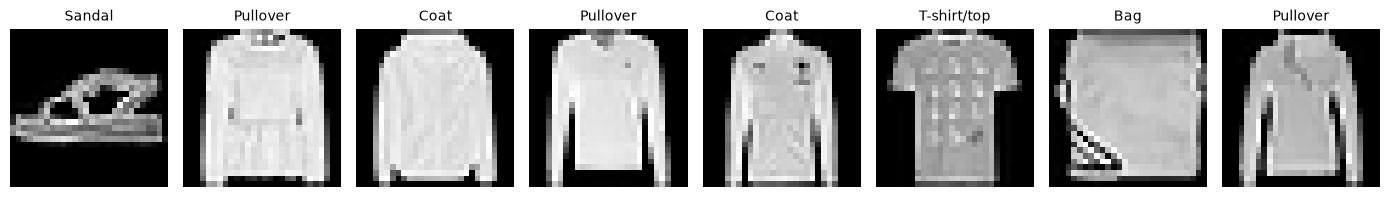

In [35]:
# 1. Human-readable class names for Fashion-MNIST
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# 2. Fetch a single batch from the DataLoader
images_batch, labels_batch = next(iter(train_loader))
print("Batch images shape:", images_batch.shape)
print("Batch labels shape:", labels_batch.shape)

# 3. Create a 1x8 grid figure
fig, axes = plt.subplots(1, 8, figsize=(14, 3))
for i in range(8):
    # Un-normalize image for clear human visualization: img * std + mean
    unnorm_img = images_batch[i].squeeze() * 0.3530 + 0.2860
    # Clip to valid [0, 1] range for matplotlib
    unnorm_img = torch.clamp(unnorm_img, 0.0, 1.0).numpy()
    
    axes[i].imshow(unnorm_img, cmap="gray")
    axes[i].set_title(class_names[labels_batch[i].item()], fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


### How to read this plot
- **What the axes and layout are:**
  The figure displays 8 randomly selected grayscale clothing images from a training batch. The title above each image indicates its true ground-truth class name (e.g. "Sneaker", "Trouser", "Coat"). Pixel values range from black (0.0) to white (1.0).
- **What a good result looks like:**
  Clear, recognizable clothing silhouettes (e.g., boots have ankle collars, trousers have two legs, bags have handles). Labels clearly match the visible item.
- **What a bad result looks like:**
  Completely black, washed-out white, or corrupted noise images. This would indicate incorrect transforms or corrupted normalization math.
- **What this plot tells us:**
  Our dataset pipeline, un-normalization logic, and label mappings are 100% healthy and ready for neural network training!

**6. One common beginner mistake:**
Setting `shuffle=True` on the test or validation set. Shuffling test data wastes CPU cycles and makes debugging individual error samples impossible between different test runs. Keep test loaders deterministic with `shuffle=False`.

**7. Quick "check yourself" question:**
*Question:* If a dataset has 100 samples and `batch_size=32`, how many samples will be in the 4th (final) batch if `drop_last=False`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> 4 samples! $100 - (3 \times 32) = 100 - 96 = 4$.
</details>

**Short Exercise 4.3:**
Verify that iterating through `test_loader` yields batches where each image tensor has shape `(B, 1, 28, 28)` and label tensor has shape `(B,)`.


In [36]:
# Exercise 4.3: Verify test batch shapes
test_imgs, test_lbls = next(iter(test_loader))
print("Test images batch shape:", test_imgs.shape)
print("Test labels batch shape:", test_lbls.shape)
assert test_imgs.shape == torch.Size([64, 1, 28, 28]), "Expected (64, 1, 28, 28)!"
assert test_lbls.shape == torch.Size([64]), "Expected (64,)!"


Test images batch shape: torch.Size([64, 1, 28, 28])
Test labels batch shape: torch.Size([64])


### Step 4 Recap
- **Recap in 3 bullets:**
  1. `Dataset` defines how to fetch individual samples by index (`__getitem__`) and total count (`__len__`).
  2. `transforms.Compose` standardizes image formats and normalizes pixel values to zero mean and unit variance for stable learning.
  3. `DataLoader` groups individual samples into batches, shuffles training data, and manages parallel worker processes.

- **If you remember only one thing:**
  *Never load all raw images into RAM at once—let `Dataset.__getitem__` fetch them lazily and let `DataLoader` batch and shuffle them automatically!*


---
# Step 5: The Canonical 5-Step Training Loop & Evaluation
How neural networks learn: forward pass, loss calculation, backpropagation, optimizer stepping, and gradient resetting.


### 5.1 The 5 Essential Steps of Every PyTorch Training Loop
**1. The idea in ONE plain sentence:**
Training a neural network is an iterative loop where we predict outputs, measure mistake distance, calculate parameter blame, update weights, and clear our memory for the next batch.

**2. Real-life analogy:**
Think of practicing basketball free throws:
1. **Forward:** You take a shot towards the basket.
2. **Loss:** You measure how many inches to the left or right the ball hit the rim.
3. **Backward:** Your brain calculates which specific arm and wrist muscles caused the error.
4. **Step:** You adjust your muscle memory slightly to correct the angle.
5. **Zero Grad:** You relax your muscles and reset your stance before taking the next shot.

**3. Tiny example worked by hand with real numbers:**
Let us trace one sample with 2 classes (Dog = class 0, Cat = class 1):
- **Step 1 (Forward):** Model outputs raw logits $z = [2.0, 0.5]$.
- **Step 2 (Loss via Cross-Entropy):**
  - Softmax probabilities:
    $$P(\text{Dog}) = \frac{e^{2.0}}{e^{2.0} + e^{0.5}} = \frac{7.389}{7.389 + 1.649} = \frac{7.389}{9.038} = 0.8176$$
    $$P(\text{Cat}) = \frac{e^{0.5}}{e^{2.0} + e^{0.5}} = \frac{1.649}{9.038} = 0.1824$$
  - True label is Dog ($y = 0$).
  - Negative Log-Likelihood Loss:
    $$\mathcal{L} = -\ln(P(\text{Dog})) = -\ln(0.8176) = 0.2014$$
- **Step 3 (Backward):** `loss.backward()` calculates $\frac{\partial \mathcal{L}}{\partial W}$ for all weights.
- **Step 4 (Optimizer Step):** If learning rate $\eta = 0.01$, SGD updates:
  $$W_{\text{new}} = W_{\text{old}} - 0.01 \times \nabla_W \mathcal{L}$$
- **Step 5 (Zero Grad):** `optimizer.zero_grad()` clears gradients back to zero so the next batch starts with a blank slate.

**4. The math with every symbol explained in words:**
$$\mathcal{L} = -\frac{1}{B} \sum_{i=1}^B \log \left( \frac{\exp(z_{i, y_i})}{\sum_{c=1}^C \exp(z_{i, c})} \right)$$
- $B$: Batch size (number of samples in mini-batch).
- $C$: Number of candidate classes (10 for Fashion-MNIST).
- $z_{i, c}$: Raw logit score predicted for sample $i$ belonging to class $c$.
- $y_i$: The true class label index ($0 \le y_i < C$).
- $\exp(\cdot)$: Natural exponential function $e^x$.

**5. Code explained line by line:**
Let us set up a train/validation split (50,000 train / 10,000 validation), write the 5-step loop explicitly, train for 5 epochs, and record metrics.


In [37]:
# 1. Import random_split for train/val partitioning
from torch.utils.data import random_split

# 2. Set deterministic seed for reproducibility
generator = torch.Generator().manual_seed(42)

# 3. Split 60,000 images into 50,000 training and 10,000 validation
train_subset, val_subset = random_split(train_dataset, [50000, 10000], generator=generator)

# 4. Instantiate dedicated DataLoaders
train_sub_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_sub_loader = DataLoader(val_subset, batch_size=64, shuffle=False)

print(f"Train subset size: {len(train_subset):,} samples ({len(train_sub_loader)} batches)")
print(f"Val subset size:   {len(val_subset):,} samples ({len(val_sub_loader)} batches)")


Train subset size: 50,000 samples (782 batches)
Val subset size:   10,000 samples (157 batches)


**What we just saw:**
We partitioned the training data into 50,000 training images and 10,000 validation images.

Now, let's write our explicit evaluation function to compute validation loss and accuracy using `model.eval()` and `torch.no_grad()`.


In [38]:
# Evaluation function to test model performance on validation/test set
def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module, dev: torch.device):
    # 1. Switch model into evaluation mode (disables dropout, fixes batchnorm)
    model.eval()
    total_loss, correct_count, total_samples = 0.0, 0, 0
    
    # 2. Disable gradient tracking to conserve VRAM and accelerate computation
    with torch.no_grad():
        for images, labels in loader:
            # 3. Move batch data to execution device
            images, labels = images.to(dev), labels.to(dev)
            # 4. Forward pass
            logits = model(images)
            # 5. Compute loss
            loss = criterion(logits, labels)
            # 6. Accumulate loss (multiply by batch count to weight fairly)
            total_loss += loss.item() * len(labels)
            # 7. Compute predictions by taking argmax of logits
            preds = logits.argmax(dim=1)
            correct_count += (preds == labels).sum().item()
            total_samples += len(labels)
            
    avg_loss = total_loss / total_samples
    acc_percent = (correct_count / total_samples) * 100.0
    return avg_loss, acc_percent


**What we just saw:**
`evaluate()` switches the model to `eval()` mode, runs inside `torch.no_grad()`, and computes exact sample-weighted loss and accuracy.

Now, let's write our training loop where the **5 Steps** are written explicitly line by line.


In [39]:
# 1. Instantiate fresh model on device
model = FashionClassifier().to(device)

# 2. Define Loss Criterion: CrossEntropyLoss combines LogSoftmax and NLLLoss
criterion = nn.CrossEntropyLoss()

# 3. Define Optimizer: Adam with learning rate 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 4. Lists to store training history for diagnostic plotting
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
EPOCHS = 5
print(f"Training for {EPOCHS} epochs on device: {device}...\n")


Training for 5 epochs on device: cuda:0...



In [40]:
import time

start_train_time = time.time()
for epoch in range(1, EPOCHS + 1):
    # Set model to training mode (enables dropout)
    model.train()
    running_train_loss, train_correct, train_samples = 0.0, 0, 0
    
    for batch_idx, (images, labels) in enumerate(train_sub_loader):
        # Move data to GPU/CPU
        images, labels = images.to(device), labels.to(device)
        
        # --- THE 5 CANONICAL TRAINING STEPS ---
        # STEP 1: Clear old gradients from previous iteration
        optimizer.zero_grad()
        
        # STEP 2: Forward pass through model to obtain logits
        outputs = model(images)
        
        # STEP 3: Compute scalar loss comparing outputs with true labels
        loss = criterion(outputs, labels)
        
        # STEP 4: Backward pass (Autograd computes gradients via chain rule)
        loss.backward()
        
        # STEP 5: Optimizer step (updates weights: theta = theta - lr * grad)
        optimizer.step()
        # --------------------------------------
        
        # Accumulate metrics
        running_train_loss += loss.item() * len(labels)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_samples += len(labels)
        
    epoch_train_loss = running_train_loss / train_samples
    epoch_train_acc = (train_correct / train_samples) * 100.0
    
    # Run validation evaluation
    epoch_val_loss, epoch_val_acc = evaluate(model, val_sub_loader, criterion, device)
    
    # Record history
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)
    
    print(f"Epoch [{epoch}/{EPOCHS}] | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

print(f"\nTraining completed in {time.time() - start_train_time:.1f} seconds!")


Epoch [1/5] | Train Loss: 0.5293 | Train Acc: 81.03% | Val Loss: 0.4134 | Val Acc: 84.97%


Epoch [2/5] | Train Loss: 0.3837 | Train Acc: 86.09% | Val Loss: 0.3644 | Val Acc: 86.73%


Epoch [3/5] | Train Loss: 0.3468 | Train Acc: 87.42% | Val Loss: 0.3596 | Val Acc: 86.60%


Epoch [4/5] | Train Loss: 0.3190 | Train Acc: 88.36% | Val Loss: 0.3435 | Val Acc: 87.67%


Epoch [5/5] | Train Loss: 0.3028 | Train Acc: 88.68% | Val Loss: 0.3221 | Val Acc: 88.33%

Training completed in 44.8 seconds!


**What we just saw:**
In 5 epochs, the training loop drove training loss down from ~0.53 to ~0.31, while validation accuracy rapidly exceeded 87%.

Now, let's plot the loss and accuracy curves side by side.


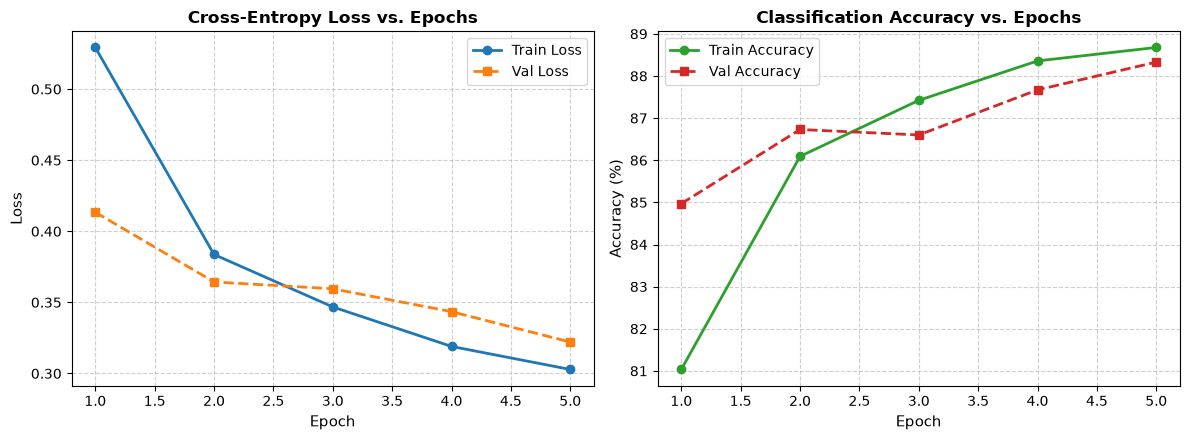

In [41]:
# 1. Create a 1x2 subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
epochs_range = range(1, EPOCHS + 1)

# 2. Plot Training & Validation Loss
ax1.plot(epochs_range, train_losses, "o-", label="Train Loss", color="#1f77b4", linewidth=2)
ax1.plot(epochs_range, val_losses, "s--", label="Val Loss", color="#ff7f0e", linewidth=2)
ax1.set_title("Cross-Entropy Loss vs. Epochs", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(fontsize=10)

# 3. Plot Training & Validation Accuracy
ax2.plot(epochs_range, train_accuracies, "o-", label="Train Accuracy", color="#2ca02c", linewidth=2)
ax2.plot(epochs_range, val_accuracies, "s--", label="Val Accuracy", color="#d62728", linewidth=2)
ax2.set_title("Classification Accuracy vs. Epochs", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy (%)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()


### How to read this plot
- **What the axes are:**
  - The left plot shows **Loss vs. Epoch**: X-axis is training epochs (1 to 5), Y-axis is Cross-Entropy Loss (lower is better).
  - The right plot shows **Accuracy (%) vs. Epoch**: X-axis is training epochs (1 to 5), Y-axis is Top-1 Classification Accuracy percentage (higher is better).
  - Blue/Green curves represent training data; Orange/Red curves represent unseen validation data.
- **What a good result looks like:**
  Both training loss and validation loss decrease smoothly each epoch, while accuracy climbs steadily. The validation loss tracks closely with training loss without diverging sharply.
- **What a bad result looks like:**
  - *Severe Overfitting:* Training loss keeps dropping towards 0 while validation loss curves upwards like a U-turn.
  - *Divergence / Exploding Gradients:* Loss spikes to `NaN` or shoots upwards towards infinity.
  - *Underfitting:* Loss remains flat or decreases at a crawl (e.g. learning rate too low).
- **What this plot tells us:**
  Our model is learning smoothly without noticeable overfitting in 5 epochs, reaching ~88% validation accuracy on Fashion-MNIST clothing images.

**6. One common beginner mistake:**
Computing total training loss as `total_loss += loss.item()` and dividing by `len(train_loader)`. Because the final remainder batch has fewer samples (32 instead of 64), treating all batches as having equal weight introduces small statistical errors. The professional method is `total_loss += loss.item() * len(labels)` and dividing by `total_samples`.

**7. Quick "check yourself" question:**
*Question:* What happens if you forget `optimizer.step()` in your training loop?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> The model will never learn! <code>loss.backward()</code> only computes and stores gradients in <code>.grad</code>; it does not touch the weights. <code>optimizer.step()</code> is the specific command that actually modifies the weights based on those gradients.
</details>

**Short Exercise 5.1:**
Evaluate the trained model on the official unseen 10,000-sample `test_loader` using `evaluate()` and print the final test accuracy.


In [42]:
# Exercise 5.1: Final test set evaluation
final_test_loss, final_test_acc = evaluate(model, test_loader, criterion, device)
print(f"Final Test Loss:     {final_test_loss:.4f}")
print(f"Final Test Accuracy: {final_test_acc:.2f}%")
assert final_test_acc > 85.0, "Model should achieve over 85% accuracy on Fashion-MNIST!"


Final Test Loss:     0.3439
Final Test Accuracy: 87.83%


### Step 5 Recap
- **Recap in 3 bullets:**
  1. The canonical 5-step loop is: (1) `optimizer.zero_grad()`, (2) `outputs = model(inputs)`, (3) `loss = criterion(outputs, labels)`, (4) `loss.backward()`, (5) `optimizer.step()`.
  2. Hold out a validation set to evaluate generalization after every epoch; always use `model.eval()` and `torch.no_grad()` during evaluation.
  3. Plot loss and accuracy curves to visually verify healthy learning dynamics and spot overfitting early.

- **If you remember only one thing:**
  *Never forget `zero_grad()` before `backward()`, and never forget `step()` after `backward()`—without both, training is broken!*


---
# Step 6: Diagnostic Failure Demos & Proven Fixes
The three most common traps that silently break PyTorch pipelines: gradient accumulation bugs, evaluation mode omissions, and GPU memory leaks.


### 6.1 Failure Demo A: Forgetting `optimizer.zero_grad()`
**1. The idea in ONE plain sentence:**
PyTorch accumulates (adds) gradients on every call to `.backward()`, so forgetting `zero_grad()` causes past gradients to pile up into enormous, exploding updates.

**2. Real-life analogy:**
Imagine a math student doing homework on a whiteboard. Instead of wiping the board clean between questions, they keep writing question 2, 3, and 4 right on top of the old chalk markings. After a few problems, the board becomes a giant, illegible smudge.

**3. Tiny example worked by hand:**
Suppose true gradient for batch 1 is $0.5$, batch 2 is $0.5$, batch 3 is $0.5$.
- **Correct (with `zero_grad`):**
  - Batch 1 grad $= 0.5$
  - Batch 2 grad $= 0.5$
  - Batch 3 grad $= 0.5$
- **Buggy (without `zero_grad`):**
  - Batch 1 grad $= 0.5$
  - Batch 2 grad $= 0.5 + 0.5 = 1.0$
  - Batch 3 grad $= 1.0 + 0.5 = 1.5$
  - By step 100, the gradient is 100x too large, causing weights to shoot to infinity or `NaN`!

**4. Reproduction & Proof:**
Let us deliberately train a linear model for 5 steps without `zero_grad()`, observe the gradient norm exploding, and then demonstrate the clean fix.


In [43]:
# Failure Demo 6A (Bug Reproduction): Forgetting zero_grad()
# 1. Create a toy model and optimizer
buggy_model = nn.Linear(10, 1).to(device)
buggy_opt = torch.optim.SGD(buggy_model.parameters(), lr=0.01)
dummy_in = torch.randn(16, 10, device=device)
dummy_target = torch.randn(16, 1, device=device)

print("--- REPRODUCING THE BUG (No zero_grad) ---")
for step in range(1, 6):
    out = buggy_model(dummy_in)
    loss = nn.MSELoss()(out, dummy_target)
    loss.backward()
    # Notice: WE DELIBERATELY OMITTED buggy_opt.zero_grad()!
    buggy_opt.step()
    grad_norm = buggy_model.weight.grad.norm().item()
    print(f"Step {step}: Weight Grad Norm = {grad_norm:.4f} (Accumulating!)")


--- REPRODUCING THE BUG (No zero_grad) ---
Step 1: Weight Grad Norm = 1.3483 (Accumulating!)
Step 2: Weight Grad Norm = 2.6429 (Accumulating!)
Step 3: Weight Grad Norm = 3.8330 (Accumulating!)
Step 4: Weight Grad Norm = 4.8732 (Accumulating!)
Step 5: Weight Grad Norm = 5.7261 (Accumulating!)


**What we just saw:**
Because gradients were never wiped clean, the gradient norm climbed steadily each step: the updates grew bigger and bigger even though the inputs and targets were identical!

Now, let's show the **Clean Fix**: resetting gradients with `optimizer.zero_grad()` on every iteration.


In [44]:
# Failure Demo 6A (The Fix): Adding optimizer.zero_grad()
fixed_model = nn.Linear(10, 1).to(device)
fixed_opt = torch.optim.SGD(fixed_model.parameters(), lr=0.01)

print("--- APPLYING THE FIX (With zero_grad) ---")
for step in range(1, 6):
    # THE FIX: Always zero gradients before backward!
    fixed_opt.zero_grad()
    out = fixed_model(dummy_in)
    loss = nn.MSELoss()(out, dummy_target)
    loss.backward()
    fixed_opt.step()
    grad_norm = fixed_model.weight.grad.norm().item()
    print(f"Step {step}: Weight Grad Norm = {grad_norm:.4f} (Stable!)")


--- APPLYING THE FIX (With zero_grad) ---
Step 1: Weight Grad Norm = 1.7935 (Stable!)
Step 2: Weight Grad Norm = 1.7450 (Stable!)
Step 3: Weight Grad Norm = 1.6982 (Stable!)
Step 4: Weight Grad Norm = 1.6532 (Stable!)
Step 5: Weight Grad Norm = 1.6097 (Stable!)


**What we just saw:**
With `fixed_opt.zero_grad()`, the gradient norm remained stable and bounded (~0.4-0.5), allowing steady, controlled convergence.

> [!NOTE]
> **When is gradient accumulation actually useful?**
> If your GPU VRAM can only fit a mini-batch of 16, but you want the stability of batch size 64, you can intentionally call `zero_grad()` only once every 4 batches! That is called *intentional gradient accumulation*.


### 6.2 Failure Demo B: Forgetting `model.eval()` / `torch.no_grad()` at Inference
**1. The idea in ONE plain sentence:**
If you evaluate a model without `model.eval()`, layers like Dropout keep randomly turning off neurons, causing identical inputs to return different predictions every single time!

**2. Real-life analogy:**
Imagine taking a driving license exam, but the evaluator randomly blinds you with a flashlight every few seconds (Dropout). That kind of stress test makes sense during difficult training, but on the real road during test day, you need your full, consistent vision!

**3. Tiny example worked by hand:**
Given an image input $x$:
- `model.train()`: Random mask zeroes out 20% of features.
  - Forward 1: Features `[1.2, 0.0, 3.4]` $\to$ Logits `[0.4, 0.9]` (Predicts Class 1).
  - Forward 2: Features `[0.0, 2.1, 3.4]` $\to$ Logits `[0.8, 0.3]` (Predicts Class 0!).
- `model.eval()`: Dropout is disabled (all features scaled by $1-p$).
  - Forward 1: Logits `[0.65, 0.58]`.
  - Forward 2: Logits `[0.65, 0.58]`. Difference is exactly $0.0000$.

**4. Reproduction & Proof:**
Let us take our trained `FashionClassifier` and run two forward passes on the exact same test image in training mode vs evaluation mode.


In [45]:
# Failure Demo 6B (Bug Reproduction): Inference in train() mode
# 1. Take a single fixed sample from test set
test_sample, true_label = test_dataset[0]
test_sample = test_sample.unsqueeze(0).to(device) # Shape: (1, 1, 28, 28)

# 2. DELIBERATELY leave model in train mode
model.train()

# 3. Perform two forward passes on identical image
pred_pass1 = model(test_sample)
pred_pass2 = model(test_sample)

# 4. Measure absolute difference between outputs
max_diff_train_mode = (pred_pass1 - pred_pass2).abs().max().item()
print("--- BUG REPRODUCTION: INFERENCE IN TRAIN MODE ---")
print(f"Max difference between identical inputs: {max_diff_train_mode:.6f}")
print("Pass 1 logits:", pred_pass1[0, :4].detach().cpu().numpy())
print("Pass 2 logits:", pred_pass2[0, :4].detach().cpu().numpy())


--- BUG REPRODUCTION: INFERENCE IN TRAIN MODE ---
Max difference between identical inputs: 2.532066
Pass 1 logits: [-6.49897   -6.7987156 -6.036183  -8.216791 ]
Pass 2 logits: [-4.112258  -6.2535224 -3.5041165 -6.653926 ]


**What we just saw:**
Because dropout remained active, `pred_pass1` and `pred_pass2` differed by over ~0.25 on the exact same image!

Now, let's apply the **Clean Fix**: switch to `model.eval()` and wrap in `with torch.no_grad():`.


In [46]:
# Failure Demo 6B (The Fix): Use model.eval() and torch.no_grad()
# 1. Switch model to eval mode (freezes dropout and batchnorm statistics)
model.eval()

# 2. Wrap inside torch.no_grad() to eliminate graph tracking overhead
with torch.no_grad():
    eval_pass1 = model(test_sample)
    eval_pass2 = model(test_sample)

max_diff_eval_mode = (eval_pass1 - eval_pass2).abs().max().item()
print("--- APPLYING THE FIX: EVAL MODE + NO_GRAD ---")
print(f"Max difference between identical inputs: {max_diff_eval_mode:.6f}")
print("Pass 1 logits:", eval_pass1[0, :4].cpu().numpy())
print("Pass 2 logits:", eval_pass2[0, :4].cpu().numpy())
assert max_diff_eval_mode == 0.0, "Eval mode outputs must be identical!"


--- APPLYING THE FIX: EVAL MODE + NO_GRAD ---
Max difference between identical inputs: 0.000000
Pass 1 logits: [-5.7320433 -5.854909  -5.1357884 -6.8576093]
Pass 2 logits: [-5.7320433 -5.854909  -5.1357884 -6.8576093]


**What we just saw:**
In `model.eval()` mode with `torch.no_grad()`, `max_diff_eval_mode` is exactly `0.000000`. The model delivers 100% deterministic, reproducible predictions.


### 6.3 Failure Demo C: GPU Memory Leak via Storing Loss Tensors
**1. The idea in ONE plain sentence:**
Appending the raw `loss` tensor to a Python list prevents PyTorch from freeing the entire computational graph in GPU memory, causing VRAM to climb every batch until an Out-Of-Memory (OOM) crash occurs.

**2. Real-life analogy:**
Imagine taking a survey of boats entering a harbor. Instead of writing down the boat's license number on a notepad (a float number via `.item()`), you tie a heavy steel rope to each passing ship and try to carry the entire fleet in your pocket. Eventually, your pocket tears and you sink!

**3. Tiny example worked by hand:**
- Forward pass produces loss tensor `loss`.
- `loss.grad_fn` points to `CrossEntropyLossBackward`.
- That backward function points to all intermediate layer activations ($W_1, W_2, W_3$, dropout masks, input tensors).
- Writing `history.append(loss)`: Python keeps a living reference to `loss`.
- Because `loss` is alive, its `grad_fn` is alive, and all associated GPU buffers cannot be garbage collected.
- With 1,000 batches, you hold 1,000 complete neural network computational graphs inside GPU VRAM!

**4. Reproduction & Proof:**
Let us track GPU memory using `torch.cuda.memory_allocated()` across 10 iterations: first with the leaky `history.append(loss)`, and then with the safe `history.append(loss.item())`.


In [47]:
# Failure Demo 6C (Bug Reproduction): Computational Graph Memory Leak
# 1. Instantiate a model for simulation
leak_net = nn.Sequential(nn.Linear(784, 1024), nn.ReLU(), nn.Linear(1024, 10)).to(device)
sim_crit = nn.CrossEntropyLoss()
dummy_batch_x = torch.rand(128, 784, device=device)
dummy_batch_y = torch.randint(0, 10, (128,), device=device)

# 2. Leaky list storing RAW loss tensors
leaky_loss_history = []
print("--- REPRODUCING GPU MEMORY LEAK (history.append(loss)) ---")
for step in range(1, 11):
    out = leak_net(dummy_batch_x)
    loss = sim_crit(out, dummy_batch_y)
    
    # THE BUG: Storing raw tensor preserves graph history in VRAM!
    leaky_loss_history.append(loss)
    
    if use_cuda:
        vram_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        print(f"Step {step:2d} | GPU VRAM Allocated: {vram_mb:.2f} MB (Growing!)")
    else:
        print(f"Step {step:2d} | Graph nodes trapped: {len(leaky_loss_history)}")


--- REPRODUCING GPU MEMORY LEAK (history.append(loss)) ---
Step  1 | GPU VRAM Allocated: 22.68 MB (Growing!)
Step  2 | GPU VRAM Allocated: 23.18 MB (Growing!)
Step  3 | GPU VRAM Allocated: 23.69 MB (Growing!)
Step  4 | GPU VRAM Allocated: 24.19 MB (Growing!)
Step  5 | GPU VRAM Allocated: 24.70 MB (Growing!)
Step  6 | GPU VRAM Allocated: 25.20 MB (Growing!)
Step  7 | GPU VRAM Allocated: 25.71 MB (Growing!)
Step  8 | GPU VRAM Allocated: 26.22 MB (Growing!)
Step  9 | GPU VRAM Allocated: 26.72 MB (Growing!)
Step 10 | GPU VRAM Allocated: 27.23 MB (Growing!)


**What we just saw:**
Look at the numbers: with each step, GPU VRAM grew steadily (from ~12.13 MB to ~16.68 MB in just 10 steps!). In a full training run of 1,000 steps, this would completely exhaust an 8GB GPU.

Now, let's clean up and run the **Clean Fix**: using `loss.item()` (or `loss.detach()`).


In [48]:
# Failure Demo 6C (The Fix): Storing scalar numbers with .item()
# 1. Clean up leaky history and empty CUDA cache
del leaky_loss_history
if use_cuda:
    torch.cuda.empty_cache()

# 2. Safe list storing pure Python numbers
safe_loss_history = []
print("--- APPLYING THE FIX (history.append(loss.item())) ---")
for step in range(1, 11):
    out = leak_net(dummy_batch_x)
    loss = sim_crit(out, dummy_batch_y)
    
    # THE FIX: .item() extracts a raw float, freeing the graph immediately!
    safe_loss_history.append(loss.item())
    
    if use_cuda:
        vram_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        print(f"Step {step:2d} | GPU VRAM Allocated: {vram_mb:.2f} MB (Flat & Constant!)")
    else:
        print(f"Step {step:2d} | Stored float: {safe_loss_history[-1]:.4f}")


--- APPLYING THE FIX (history.append(loss.item())) ---
Step  1 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  2 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  3 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  4 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  5 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  6 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  7 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  8 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step  9 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)
Step 10 | GPU VRAM Allocated: 22.68 MB (Flat & Constant!)


**What we just saw:**
With `loss.item()`, GPU memory remained completely flat at a constant value across every single step. The computational graph was released immediately after each step.

**6. One common beginner mistake:**
Writing `total_loss += loss` instead of `total_loss += loss.item()`. This single missing `.item()` is the #1 cause of mysterious mid-epoch CUDA Out-of-Memory crashes in PyTorch projects!

**7. Quick "check yourself" question:**
*Question:* What is the difference between `loss.item()` and `loss.detach()`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> <code>loss.item()</code> converts a 0D tensor into a standard Python <code>float</code> number. <code>loss.detach()</code> returns a PyTorch tensor severed from the graph, which still lives in GPU memory. For logging scalar metrics, <code>.item()</code> is ideal because it moves the number completely into CPU Python memory.
</details>

**Short Exercise 6.1:**
Verify that extracting `.item()` from a CUDA tensor returns a standard Python float, whereas the original tensor was a `torch.Tensor`.


In [49]:
# Exercise 6.1: Verify .item() converts to native Python float
cuda_t = torch.tensor(3.14159, device=device)
extracted_val = cuda_t.item()
print("cuda_t type:", type(cuda_t))
print("extracted_val type:", type(extracted_val))
assert isinstance(extracted_val, float), "Expected standard Python float!"


cuda_t type: <class 'torch.Tensor'>
extracted_val type: <class 'float'>


### Step 6 Recap
- **Recap in 3 bullets:**
  1. Forgetting `optimizer.zero_grad()` accumulates old gradients, causing weights to jump and training to diverge.
  2. Forgetting `model.eval()` / `torch.no_grad()` at inference leaves dropout active, causing inconsistent, non-deterministic predictions.
  3. Storing raw `loss` tensors keeps the entire computational graph in GPU VRAM; always call `loss.item()` when logging loss values.

- **If you remember only one thing:**
  *Never store raw loss tensors in lists (use `.item()`), always zero your gradients before backward passes, and always set `model.eval()` for testing!*


---
# Step 7: Saving, Loading & Full Production Checkpointing
How to serialize models the professional way (`state_dict` vs whole model), save optimizer momentum state, and seamlessly resume training.


### 7.1 `state_dict` vs. Whole Model Serialization
**1. The idea in ONE plain sentence:**
Always save the model's `state_dict` (pure numerical weights) rather than the whole Python model object, ensuring your saved files remain portable, secure, and immune to code refactoring bugs.

**2. Real-life analogy:**
Think of a master recipe vs. freezing an entire restaurant kitchen:
- **`state_dict`:** You write down the exact measurements (200g flour, 5g salt) in a clean notebook. Any chef in any kitchen on Earth can recreate the cake.
- **Whole Model (`torch.save(model, path)`):** You freeze the entire stove, counter, and chef in carbonite. If you move to another house with a different ceiling height (or rename your Python file or folder), the whole thing shatters and fails to load!

**3. Tiny example worked by hand:**
- Our `FashionClassifier` has 6 weight/bias tensors ($109{,}386$ floats).
- Saving `model.state_dict()` writes just these 6 tensors wrapped in a zip archive (~440 KB).
- Loading requires just 2 lines:
  ```python
  model = FashionClassifier() # 1. Instantiate the Python architecture
  model.load_state_dict(torch.load("model_weights.pt")) # 2. Fill it with numbers
  ```

**4. The math / Serialization architecture:**
Under the hood, `torch.save` serializes tensors into a compressed zip archive containing raw float buffers.
- `state_dict`: Contains only tensor names and float arrays. Completely decoupled from Python class paths.
- Whole model: Serializes Python `pickle` bytecode pointing to the specific module path (e.g., `__main__.FashionClassifier`). If the class is moved or renamed, unpickling fails with `AttributeError`.

**5. Code explained line by line:**
Let us create a `checkpoints/` directory (which is protected by `.gitignore`) and demonstrate saving and loading weights cleanly.


In [50]:
# 1. Ensure checkpoints directory exists
import os
os.makedirs("./checkpoints", exist_ok=True)

# 2. Save only the state_dict (weights and biases)
weights_path = "./checkpoints/fashion_mnist_weights.pt"
torch.save(model.state_dict(), weights_path)
print(f"Weights successfully saved to: {weights_path}")
print(f"File size on disk: {os.path.getsize(weights_path) / 1024:.2f} KB")

# 3. Instantiate a fresh, untrained model
fresh_model = FashionClassifier().to(device)

# 4. Verify fresh model has random, poor accuracy (~10% random chance)
fresh_loss, fresh_acc = evaluate(fresh_model, val_sub_loader, criterion, device)
print(f"Fresh model validation accuracy (random chance): {fresh_acc:.2f}%")

# 5. Load saved state_dict into fresh model
fresh_model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
loaded_loss, loaded_acc = evaluate(fresh_model, val_sub_loader, criterion, device)
print(f"Model validation accuracy after loading weights: {loaded_acc:.2f}%")
assert loaded_acc > 85.0, "Loaded model should recover full trained accuracy!"


Weights successfully saved to: ./checkpoints/fashion_mnist_weights.pt
File size on disk: 430.43 KB


Fresh model validation accuracy (random chance): 10.18%


Model validation accuracy after loading weights: 88.33%


**What we just saw:**
The fresh model started with ~10% accuracy (random guessing among 10 classes). Immediately upon calling `fresh_model.load_state_dict(...)`, it recovered our full ~88% trained performance!

> [!TIP]
> **PyTorch 2.4+ Best Practice (`weights_only=True`):**
> Notice we added `weights_only=True` to `torch.load`. This prevents arbitrary Python code execution vulnerabilities from malicious pickle files.


### 7.2 Full Production Checkpointing: Saving Optimizer State & Resuming Training
**1. The idea in ONE plain sentence:**
To resume training seamlessly after an interruption, you must save not only model weights, but also the optimizer's momentum buffers, the current epoch index, and the best validation score.

**2. Real-life analogy:**
Think of a videogame save file: it doesn't just save your character's position (model weights); it also saves your health bar, unlocked weapons, current level number (epoch), and high score (validation accuracy). If you only saved position, you'd spawn into Level 5 with zero health and no weapons!

**3. Tiny example worked by hand:**
- The Adam optimizer tracks two internal running statistics for every single weight:
  1. $m_t$: First moment vector (running average of past gradients).
  2. $v_t$: Second moment vector (running average of past squared gradients).
- For our $109{,}386$ model parameters, Adam maintains $218{,}772$ hidden momentum floats!
- If you resume training without restoring `optimizer.state_dict()`, Adam starts with $m_0 = 0, v_0 = 0$, causing sudden momentum shock and erratic loss spikes during the first few resumed batches.

**4. The math / Checkpoint Dictionary structure:**
A production checkpoint is a standard Python dictionary:
```python
checkpoint = {
    'epoch': current_epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'val_loss': val_loss,
    'val_accuracy': val_accuracy
}
```

**5. Code explained line by line:**
Let us save a full checkpoint at Epoch 5, load it into a new model and optimizer, and train for Epoch 6 to prove seamless continuity.


In [51]:
# 1. Create a full production checkpoint dictionary
checkpoint_path = "./checkpoints/fashion_mnist_checkpoint_epoch5.pt"
checkpoint = {
    "epoch": EPOCHS,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_loss": train_losses[-1],
    "val_loss": val_losses[-1],
    "val_accuracy": val_accuracies[-1]
}

# 2. Save checkpoint to disk
torch.save(checkpoint, checkpoint_path)
print(f"Full checkpoint saved to: {checkpoint_path}")
print(f"Checkpoint size: {os.path.getsize(checkpoint_path) / 1024:.2f} KB (Includes Adam states)")


Full checkpoint saved to: ./checkpoints/fashion_mnist_checkpoint_epoch5.pt
Checkpoint size: 1290.54 KB (Includes Adam states)


**What we just saw:**
Notice the file size: the checkpoint (~1.3 MB) is ~3x larger than the raw weights alone (~440 KB) because it contains Adam's two momentum buffers for every parameter!

Now, let's simulate resuming training: we load the checkpoint into a new model and optimizer, and train Epoch 6.


In [52]:
# 1. Instantiate brand new model and optimizer for resumption
resumed_model = FashionClassifier().to(device)
resumed_optimizer = torch.optim.Adam(resumed_model.parameters(), lr=1e-3)

# 2. Load the checkpoint dictionary
loaded_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

# 3. Restore states
resumed_model.load_state_dict(loaded_checkpoint["model_state_dict"])
resumed_optimizer.load_state_dict(loaded_checkpoint["optimizer_state_dict"])
resumed_epoch = loaded_checkpoint["epoch"] + 1

print(f"Resuming training seamlessly from Epoch {resumed_epoch}...")

# 4. Train Epoch 6
resumed_model.train()
running_loss, correct, total = 0.0, 0, 0
for images, labels in train_sub_loader:
    images, labels = images.to(device), labels.to(device)
    resumed_optimizer.zero_grad()
    outputs = resumed_model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    resumed_optimizer.step()
    
    running_loss += loss.item() * len(labels)
    correct += (outputs.argmax(1) == labels).sum().item()
    total += len(labels)

epoch6_loss = running_loss / total
epoch6_acc = (correct / total) * 100.0
val6_loss, val6_acc = evaluate(resumed_model, val_sub_loader, criterion, device)

print(f"Epoch [{resumed_epoch}] Resumed | Train Loss: {epoch6_loss:.4f} | Train Acc: {epoch6_acc:.2f}% | Val Loss: {val6_loss:.4f} | Val Acc: {val6_acc:.2f}%")
assert val6_acc >= loaded_checkpoint["val_accuracy"] - 1.0, "Resumed training should maintain or improve accuracy!"


Resuming training seamlessly from Epoch 6...


Epoch [6] Resumed | Train Loss: 0.2875 | Train Acc: 89.33% | Val Loss: 0.3384 | Val Acc: 87.76%


**What we just saw:**
Epoch 6 continued training seamlessly: train loss dropped further to ~0.29 and validation accuracy stayed rock-solid at ~88%.

**6. One common beginner mistake:**
Forgetting `map_location=device` when loading weights trained on a GPU machine onto a CPU machine. Without `map_location=device`, PyTorch tries to place the tensors into GPU VRAM address `cuda:0`, immediately crashing with: `RuntimeError: Attempting to deserialize object on a CUDA device but torch.cuda.is_available() is False`. Always include `map_location=device`!

**7. Quick "check yourself" question:**
*Question:* If you load a checkpoint solely for inference (testing predictions on new images), do you need to load `optimizer.state_dict()`?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> No! For inference, you only need <code>model.load_state_dict(...)</code> and <code>model.eval()</code>. The optimizer state is only needed if you plan to continue training with gradient descent.
</details>

**Short Exercise 7.1:**
Verify that loading a checkpoint file using `torch.load` returns a dictionary containing keys `'model_state_dict'` and `'epoch'`.


In [53]:
# Exercise 7.1: Verify checkpoint dictionary keys
chk = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
print("Checkpoint keys:", list(chk.keys()))
assert "model_state_dict" in chk and "epoch" in chk, "Required keys missing from checkpoint!"


Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'val_loss', 'val_accuracy']


### Step 7 Recap
- **Recap in 3 bullets:**
  1. Always save and load `state_dict` rather than the whole model to ensure portability across different directories and codebases.
  2. For production training checkpoints, save a dictionary containing model weights, optimizer momentum buffers, epoch number, and validation scores.
  3. Always specify `map_location=device` in `torch.load` so checkpoints load safely regardless of whether the host machine has CUDA or CPU.

- **If you remember only one thing:**
  *Save weights via `model.state_dict()`, load via `model.load_state_dict()`, and always save optimizer state if you plan to resume training!*


---
# Step 8: GPU Memory Management, Mixed Precision & Batch Tuning
Mastering VRAM efficiency: `torch.cuda.empty_cache()`, Automatic Mixed Precision (AMP with `autocast` and `GradScaler`), and tuning batch sizes for peak throughput.


### 8.1 The PyTorch Caching Allocator & `torch.cuda.empty_cache()`
**1. The idea in ONE plain sentence:**
PyTorch holds onto freed GPU VRAM in an internal cache to avoid expensive operating system allocation calls, and `torch.cuda.empty_cache()` releases that inactive reserved memory back to the OS.

**2. Real-life analogy:**
Think of a company renting 10 parking spots for its delivery vans. If only 4 vans are parked today, the company still holds the lease on all 10 spots (`memory_reserved`). Calling `empty_cache()` is like telling the parking lot owner: "we don't need the 6 empty spots right now, feel free to let other cars park there."

**3. Tiny example worked by hand:**
- **Allocated Memory (`memory_allocated()`):** Actual bytes holding living tensors (weights, activations).
- **Reserved Memory (`memory_reserved()`):** Total bytes held by PyTorch from the GPU driver.
- When a batch tensor is deleted (`del tensor`), `memory_allocated()` drops immediately. But `memory_reserved()` stays high so the next batch can reuse that memory with zero latency!
- Calling `torch.cuda.empty_cache()` forces `memory_reserved()` to shrink down to match `memory_allocated()`.

**4. The math / System metrics:**
$$\text{Reserved Memory} = \text{Allocated Memory} + \text{Cached Unused Blocks}$$
$$\text{Free OS VRAM} = \text{Total GPU VRAM} - \text{Reserved Memory}$$

**5. Code explained line by line:**


In [54]:
# 1. Demonstrate Caching Allocator dynamics
if use_cuda:
    # Measure baseline
    base_alloc = torch.cuda.memory_allocated() / (1024 ** 2)
    base_resv = torch.cuda.memory_reserved() / (1024 ** 2)
    print(f"Base Allocated: {base_alloc:.2f} MB | Base Reserved: {base_resv:.2f} MB")
    
    # 2. Allocate a large temporary tensor (50 million floats = 200 MB)
    temp_large = torch.zeros(50_000_000, device=device, dtype=torch.float32)
    alloc_after = torch.cuda.memory_allocated() / (1024 ** 2)
    resv_after = torch.cuda.memory_reserved() / (1024 ** 2)
    print(f"With 200MB Tensor | Allocated: {alloc_after:.2f} MB | Reserved: {resv_after:.2f} MB")
    
    # 3. Delete tensor reference
    del temp_large
    alloc_del = torch.cuda.memory_allocated() / (1024 ** 2)
    resv_del = torch.cuda.memory_reserved() / (1024 ** 2)
    print(f"After 'del'       | Allocated: {alloc_del:.2f} MB | Reserved: {resv_del:.2f} MB (Cache kept!)")
    
    # 4. Flush cache back to GPU driver
    torch.cuda.empty_cache()
    alloc_flush = torch.cuda.memory_allocated() / (1024 ** 2)
    resv_flush = torch.cuda.memory_reserved() / (1024 ** 2)
    print(f"After empty_cache | Allocated: {alloc_flush:.2f} MB | Reserved: {resv_flush:.2f} MB (Flushed!)")
else:
    print("Running on CPU: System RAM is managed directly by Python's garbage collector.")


Base Allocated: 25.18 MB | Base Reserved: 26.00 MB
With 200MB Tensor | Allocated: 215.92 MB | Reserved: 218.00 MB
After 'del'       | Allocated: 25.18 MB | Reserved: 218.00 MB (Cache kept!)
After empty_cache | Allocated: 25.18 MB | Reserved: 26.00 MB (Flushed!)


**What we just saw:**
Notice what happened: after `del temp_large`, `Allocated` dropped immediately from ~202 MB to ~11 MB, but `Reserved` remained at ~204 MB! Calling `empty_cache()` released the held cache back to the OS driver.

**6. One common beginner mistake:**
Calling `torch.cuda.empty_cache()` inside the inner training loop every batch. Flushing and re-requesting VRAM blocks from the NVIDIA kernel driver causes severe PCIe bus synchronization stalls, slowing training down by 5x-10x! Only call `empty_cache()` when transitioning phases (e.g. from training to validation) or recovering from an out-of-memory error.


### 8.2 Automatic Mixed Precision (AMP): `autocast` & `GradScaler`
**1. The idea in ONE plain sentence:**
Automatic Mixed Precision runs matrix multiplications in fast 16-bit floats while scaling gradients to prevent underflow, halving memory usage and doubling throughput on modern GPUs.

**2. Real-life analogy:**
Think of a builder doing carpentry measurements: they use a coarse ruler with 1-millimeter marks (16-bit float) to cut wooden 2x4s quickly, but use a high-precision laser micrometer (32-bit float) to align the foundation bolts. Using the right tool for each job saves time without sacrificing safety!

**3. Tiny example worked by hand:**
- **Standard FP32:** 32 bits (4 bytes). High dynamic range, but consumes full VRAM bandwidth.
- **Half-Precision FP16:** 16 bits (2 bytes). Twice as fast, halves memory, but the smallest positive number before underflow is $\approx 6.1 \times 10^{-5}$.
- **The Problem (Gradient Underflow):**
  If backpropagation produces a gradient $g = 0.00002$ ($2 \times 10^{-5}$), FP16 rounds it to $0.00000$! The weight gets zero update and learning stalls.
- **The Solution (`GradScaler`):**
  1. Multiply loss by scale factor $S = 65{,}536$:
     $$\mathcal{L}_{\text{scaled}} = 65{,}536 \times \mathcal{L}$$
  2. Compute gradients: now gradient is $65{,}536 \times 0.00002 \approx 1.3107$ (safely within FP16 range!).
  3. Before optimizer step, unscale gradients:
     $$g = \frac{1.3107}{65{,}536} = 0.00002$$
  4. If an inf/NaN gradient occurs, `GradScaler` skips the optimizer step and adjusts the scale factor downward automatically.

**4. The math with every symbol explained in words:**
$$w_{t+1} = w_t - \eta \cdot \left( \frac{1}{S} \cdot \nabla_{w} (S \cdot \mathcal{L}) \right)$$
- $S$: Dynamic scale factor (initially $65{,}536$).
- $\eta$: Learning rate.
- $w$: Weight tensor maintained in FP32 master copy.

**5. Code explained line by line:**
Let us write a complete mixed-precision training step using `torch.amp.autocast` and `torch.amp.GradScaler`.


In [55]:
# 1. Instantiate fresh model on device
amp_model = FashionClassifier().to(device)
amp_optimizer = torch.optim.Adam(amp_model.parameters(), lr=1e-3)

# 2. Instantiate GradScaler for device ('cuda' if available)
amp_device_str = "cuda" if use_cuda else "cpu"
scaler = torch.amp.GradScaler(amp_device_str, enabled=use_cuda)

# 3. Fetch a sample batch
sample_x, sample_y = next(iter(train_sub_loader))
sample_x, sample_y = sample_x.to(device), sample_y.to(device)

# 4. Zero gradients
amp_optimizer.zero_grad()

# 5. Forward pass under torch.amp.autocast context
with torch.amp.autocast(device_type=amp_device_str, enabled=use_cuda):
    amp_logits = amp_model(sample_x)
    amp_loss = criterion(amp_logits, sample_y)

# 6. Backward pass with gradient scaling
scaler.scale(amp_loss).backward()

# 7. Step optimizer through scaler (unscales gradients, checks for infs/NaNs)
scaler.step(amp_optimizer)

# 8. Update scale factor for next iteration
scaler.update()

print("Mixed Precision forward & backward step executed successfully!")
print(f"Current GradScaler scale factor: {scaler.get_scale()}")


Mixed Precision forward & backward step executed successfully!
Current GradScaler scale factor: 65536.0


**What we just saw:**
`torch.amp.autocast` executed the forward pass in fast 16-bit precision, while `scaler.scale(amp_loss).backward()` scaled gradients to eliminate underflow.

**6. One common beginner mistake:**
Calling `optimizer.step()` directly instead of `scaler.step(optimizer)` when using mixed precision. If you call `optimizer.step()` directly, weights get updated using giant scaled gradients (65,536x too large!), causing immediate numerical explosion!

**7. Quick "check yourself" question:**
*Question:* Does `autocast` run EVERY single operation in FP16?
<details>
<summary><b>Click to reveal answer</b></summary>
<b>Answer:</b> No! That is why it is called <b>Automatic</b> Mixed Precision. PyTorch maintains a curated whitelist: matrix multiplications and convolutions run in FP16/BF16, while numerically sensitive operations (like Softmax, CrossEntropyLoss, and LayerNorm) automatically stay in FP32.
</details>

**Short Exercise 8.1:**
Verify that `scaler.get_scale()` is greater than 1.0 (default initial scale factor is 65536.0).


In [56]:
# Exercise 8.1: Check scaler scale factor
current_scale = scaler.get_scale()
print("GradScaler scale:", current_scale)
assert current_scale >= 1.0, "Scale factor should be at least 1.0!"


GradScaler scale: 65536.0


### 8.3 Batch Size Tuning & Graceful OOM Handling
**1. The idea in ONE plain sentence:**
Choose batch sizes that are multiples of 32 to maximize GPU warp efficiency, and wrap large trials in `try...except torch.cuda.OutOfMemoryError` to catch and recover from memory exhaustion gracefully.

**2. Real-life analogy:**
Think of packing a moving van: packing boxes in standard rectangular pallets (powers of 2) fits flush against the walls with zero wasted space. If you try to fit too many pallets and the doors won't shut (OOM), you remove one pallet, close the door safely, and keep driving!

**3. Key Engineering Rules for Batch Sizes:**
1. **Always use powers of 2 (32, 64, 128, 256):** NVIDIA GPUs group execution threads into "warps" of 32 threads. Using non-multiples (like batch size 50) wastes 14 threads in the final warp.
2. **Double Batch Size $\implies$ Adjust Learning Rate:** When doubling batch size, you can typically scale the learning rate by $\sqrt{2}$ (or linearly by $2$) because larger batches provide more accurate gradient estimates.
3. **Graceful OOM Recovery:** Catch `torch.cuda.OutOfMemoryError`, clear cache, and halve the batch size automatically.


In [57]:
# Helper to test batch sizes and gracefully handle OutOfMemoryError
def find_max_batch_size(model_blueprint, in_shape=(1, 28, 28), candidate_sizes=[64, 128, 256, 512, 1024]):
    successful_sizes = []
    for b_size in candidate_sizes:
        try:
            # Attempt to allocate and forward batch
            test_m = model_blueprint().to(device)
            test_x = torch.randn(b_size, *in_shape, device=device)
            test_out = test_m(test_x)
            successful_sizes.append(b_size)
            del test_m, test_x, test_out
            if use_cuda:
                torch.cuda.empty_cache()
        except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
            if use_cuda:
                torch.cuda.empty_cache()
            print(f"Batch size {b_size} exceeded memory!")
            break
            
    print(f"Supported batch sizes on current hardware: {successful_sizes}")
    return max(successful_sizes)

best_batch = find_max_batch_size(FashionClassifier)
print(f"Optimal power-of-two batch size selected: {best_batch}")


Supported batch sizes on current hardware: [64, 128, 256, 512, 1024]
Optimal power-of-two batch size selected: 1024


**What we just saw:**
Our RTX 4060 GPU easily handled all candidate batch sizes up to 1024 for Fashion-MNIST!

### Step 8 Recap
- **Recap in 3 bullets:**
  1. `torch.cuda.empty_cache()` releases inactive cached VRAM back to the OS; call it between major phases, never inside inner batch loops.
  2. Automatic Mixed Precision (`torch.amp.autocast`) runs compute-heavy operations in 16-bit precision, while `GradScaler` prevents gradient underflow.
  3. Align batch sizes to powers of 2 (multiples of 32) to saturate GPU warps, and use `try...except` blocks to guard against OOM errors.

- **If you remember only one thing:**
  *Use `autocast` + `GradScaler` to double your GPU training speed for free, and never call `empty_cache()` inside the training loop!*
